# CS3807 — Deep Learning Laboratory Experiment 8 & 9 : Effect of Attention Type and Attention Position in a Pretrained ResNet50

## 0. Setup

In [1]:
# ======================================================================
# 0. Setup : imports, GPU, reproducibility, folders, hyper-parameters
# ======================================================================
import os, gc, time, math, random, shutil, warnings, logging
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'          # hide TensorFlow C++ info / warnings
os.environ['PYTHONWARNINGS'] = 'ignore'
logging.getLogger('tensorflow').setLevel(logging.ERROR)
logging.getLogger('absl').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
tf.get_logger().setLevel('ERROR')
tf.autograph.set_verbosity(0)
try:
    import absl.logging
    absl.logging.set_verbosity(absl.logging.ERROR)
except Exception:
    pass

gpus = tf.config.list_physical_devices('GPU')
for g in gpus:
    try:
        tf.config.experimental.set_memory_growth(g, True)
    except Exception as e:
        print('Could not set memory growth:', e)

import tensorflow_datasets as tfds
import keras
from keras import layers, ops
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from IPython.display import display, FileLink
warnings.filterwarnings('ignore')                 # re-apply after library imports

assert int(keras.__version__.split('.')[0]) >= 3, 'This notebook expects Keras 3 (default on Kaggle).'
print(f'TensorFlow {tf.__version__} | Keras {keras.__version__} | GPUs: {[g.name for g in gpus]}')

# ---------------- reproducibility ----------------
SEED = 42
def set_seed(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    keras.utils.set_random_seed(seed)
set_seed()

# ---------------- folders ----------------
OUT_DIR = 'outputs'
FIG_DIR = os.path.join(OUT_DIR, 'figures')
CKPT_DIR = '_ckpt'   # temporary weights for visualisation/resume (NOT inside outputs/, NOT zipped)
# Remove figures / tables left over from an earlier version of this notebook
# (training results + _ckpt/ are kept so finished models are not retrained)
shutil.rmtree(FIG_DIR, ignore_errors=True)
KEEP_CSV = {'all_model_results.csv', 'all_training_histories.csv', 'all_test_predictions.csv'}
if os.path.isdir(OUT_DIR):
    for f in os.listdir(OUT_DIR):
        if f.endswith('.csv') and f not in KEEP_CSV:
            os.remove(os.path.join(OUT_DIR, f))
for d in (OUT_DIR, FIG_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)

# ---------------- hyper-parameters (identical for every model) ----------------
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS_HEAD = 10          # phase 1 : ResNet50 frozen, attention + classifier trained
EPOCHS_FT = 10            # phase 2 : conv5_x unfrozen (BatchNorm kept frozen)
EPOCHS_TOTAL = EPOCHS_HEAD + EPOCHS_FT
LR_HEAD = 1e-3
LR_FT = 1e-5
DROPOUT = 0.3
REDUCTION = 16            # channel-attention reduction ratio r
SA_REDUCTION = 8          # self-attention query/key dimension d = C / 8
DEFAULT_KERNEL = 7        # spatial-attention kernel (except Experiment 5)
INFER_N, INFER_WARMUP = 200, 10
TOPK_CHANNELS = 20

# Candidate positions : position -> (stage, output layer of that stage)
POSITIONS = {
    'P1': ('conv2', 'conv2_block3_out'),
    'P2': ('conv3', 'conv3_block4_out'),
    'P3': ('conv4', 'conv4_block6_out'),
    'P4': ('conv5', 'conv5_block3_out'),
}

# Figures are saved as <plot number>_<name>.png
def save_fig(fig, name):
    path = os.path.join(FIG_DIR, f'{name}.png')
    fig.savefig(path, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Saved figure ->', path)

def save_csv(df, name, index=False, verbose=True):
    path = os.path.join(OUT_DIR, f'{name}.csv')
    df.to_csv(path, index=index)
    if verbose:
        print('Saved table  ->', path)
    return path

print('Setup complete.')

ERROR:absl:Detected mismatched Protobuf Gencode/Runtime major versions when loading tensorflow_metadata/proto/v0/anomalies.proto: gencode 6.31.1 runtime 5.29.5. Same major version is required. See Protobuf version guarantees at https://protobuf.dev/support/cross-version-runtime-guarantee.
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/__init__.py", line 79, in <module>
    from tensorflow_datasets import rlds  # pylint: disable=g-bad-import-order
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/rlds/__init__.py", line 21, in <module>
    from tensorflow_datasets.rlds import envlogger_reader
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/rlds/envlogger_reader.py", line 21, in <module>
    from tensorflow_datasets.core.utils.lazy_imports_utils import tree
  File "/usr/local/lib/python3.13/dist-packages/tensorflow_datasets/core/__init__.py", line 21, in 

TensorFlow 2.20.0 | Keras 3.13.2 | GPUs: ['/physical_device:GPU:0', '/physical_device:GPU:1']
Setup complete.


## 1. Dataset Loading and 70:15:15 Split (TensorFlow Flowers)

In [2]:
# tf_flowers : fixed, stratified 70:15:15 split reused by every experiment.
# Primary route : tensorflow_datasets.  Fallback (if tfds is broken in the Kaggle image):
# the official tf_flowers archive that TFDS itself downloads, with labels in TFDS order.
import tarfile, urllib.request
from glob import glob

TF_FLOWERS_URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz'
TFDS_CLASS_ORDER = ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']   # tfds label indices 0..4

def _resize_uint8(img):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE), method='bilinear')
    return tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8)

def load_tf_flowers():
    # ---------- route 1 : tensorflow_datasets ----------
    try:
        ds, info = tfds.load('tf_flowers', split='train', as_supervised=True,
                             with_info=True, shuffle_files=False)
        names = list(info.features['label'].names)
        X, y = [], []
        for img, lab in tfds.as_numpy(ds.map(lambda i, l: (_resize_uint8(i), l),
                                             num_parallel_calls=tf.data.AUTOTUNE)):
            X.append(img); y.append(lab)
        return np.stack(X).astype(np.uint8), np.array(y, np.int32), names, None, 'tensorflow_datasets'
    except Exception as e:
        print(f'tfds.load unavailable ({type(e).__name__}: {e})')
        print('-> loading the official tf_flowers source archive (same data TFDS uses).')

    # ---------- route 2 : official tf_flowers archive ----------
    data_dir = 'tf_flowers_raw'                      # outside outputs/, not zipped
    os.makedirs(data_dir, exist_ok=True)
    tgz = os.path.join(data_dir, 'flower_photos.tgz')
    if not os.path.exists(tgz):
        urllib.request.urlretrieve(TF_FLOWERS_URL, tgz)
    if not os.path.isdir(os.path.join(data_dir, 'flower_photos')):
        with tarfile.open(tgz) as tf_:
            tf_.extractall(data_dir)

    files, labels = [], []
    for li, cname in enumerate(TFDS_CLASS_ORDER):
        fs = sorted(glob(os.path.join(data_dir, 'flower_photos', cname, '*.jpg')))
        files += fs; labels += [li] * len(fs)
    assert len(files) == 3670, f'Expected 3670 tf_flowers images, found {len(files)}'

    def _load(path):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
        return _resize_uint8(img)

    ds = tf.data.Dataset.from_tensor_slices(files).map(_load, num_parallel_calls=tf.data.AUTOTUNE).batch(256)
    X = np.concatenate([b.numpy() for b in ds]).astype(np.uint8)
    rel = [os.path.relpath(f, os.path.join(data_dir, 'flower_photos')) for f in files]
    return X, np.array(labels, np.int32), list(TFDS_CLASS_ORDER), rel, 'official tf_flowers archive'

X_all, y_all, CLASS_NAMES, SOURCE_FILES, DATA_SOURCE = load_tf_flowers()
NUM_CLASSES = len(CLASS_NAMES)
print(f'Source: {DATA_SOURCE} | images: {X_all.shape} | classes: {CLASS_NAMES}')

idx_all = np.arange(len(y_all))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)
idx_train, idx_val, idx_test = np.sort(idx_train), np.sort(idx_val), np.sort(idx_test)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val, y_val = X_all[idx_val], y_all[idx_val]
X_test, y_test = X_all[idx_test], y_all[idx_test]
del X_all
gc.collect()
print(f'Train: {len(y_train)} | Validation: {len(y_val)} | Test: {len(y_test)}')

subset = np.empty(len(y_all), dtype=object)
subset[idx_train], subset[idx_val], subset[idx_test] = 'train', 'val', 'test'
split_df = pd.DataFrame({'tfds_index': idx_all, 'label': y_all,
                         'class': [CLASS_NAMES[i] for i in y_all], 'subset': subset})
if SOURCE_FILES is not None:
    split_df['source_file'] = SOURCE_FILES
split_df['data_source'] = DATA_SOURCE
save_csv(split_df, 'dataset_split')

dist = (split_df.groupby(['class', 'subset']).size().unstack(fill_value=0)
        .reindex(index=CLASS_NAMES, columns=['train', 'val', 'test']))
dist['total'] = dist.sum(axis=1)
dist.loc['TOTAL'] = dist.sum(axis=0)
display(dist)

tfds.load unavailable (AttributeError: module 'tensorflow_datasets' has no attribute 'load')
-> loading the official tf_flowers source archive (same data TFDS uses).


I0000 00:00:1791634696.353369      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791634696.357007      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Source: official tf_flowers archive | images: (3670, 224, 224, 3) | classes: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Train: 2569 | Validation: 550 | Test: 551
Saved table  -> outputs/dataset_split.csv


subset,train,val,test,total
class,,,,
dandelion,629,134,135,898
daisy,443,95,95,633
tulips,559,120,120,799
sunflowers,489,105,105,699
roses,449,96,96,641
TOTAL,2569,550,551,3670


## 2. Image Preprocessing, Data Augmentation and Input Pipeline

In [3]:
# ImageNet 'caffe' preprocessing expected by ResNet50 (RGB->BGR + ImageNet mean subtraction)
IMAGENET_MEAN_BGR = np.array([103.939, 116.779, 123.68], dtype=np.float32)

def resnet_preprocess_tf(x):
    x = tf.cast(x, tf.float32)
    return x[..., ::-1] - IMAGENET_MEAN_BGR

def resnet_preprocess_np(x):
    return x.astype(np.float32)[..., ::-1] - IMAGENET_MEAN_BGR

_chk = keras.applications.resnet50.preprocess_input(X_test[:4].astype(np.float32).copy())
assert np.allclose(np.asarray(_chk), resnet_preprocess_np(X_test[:4]), atol=1e-3)
print('Preprocessing identical to keras.applications.resnet50.preprocess_input')

def build_augmenter():
    """Same augmentation for every model (re-created with the same seed for every run)."""
    return keras.Sequential([
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(0.05, fill_mode='reflect', seed=SEED),        # +-18 degrees
        layers.RandomZoom(0.10, fill_mode='reflect', seed=SEED),
        layers.RandomTranslation(0.10, 0.10, fill_mode='reflect', seed=SEED),
        layers.RandomContrast(0.10, seed=SEED),
    ], name='augmentation')

def make_datasets():
    aug = build_augmenter()

    def _train_map(x, y):
        x = tf.cast(x, tf.float32)
        x = aug(x, training=True)
        x = tf.clip_by_value(x, 0.0, 255.0)
        return resnet_preprocess_tf(x), tf.one_hot(y, NUM_CLASSES)

    def _eval_map(x, y):
        return resnet_preprocess_tf(x), tf.one_hot(y, NUM_CLASSES)

    train = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
             .shuffle(len(y_train), seed=SEED, reshuffle_each_iteration=True)
             .batch(BATCH_SIZE)
             .map(_train_map, num_parallel_calls=tf.data.AUTOTUNE)
             .prefetch(tf.data.AUTOTUNE))
    val = (tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH_SIZE)
           .map(_eval_map, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(tf.data.AUTOTUNE))
    test = (tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH_SIZE)
            .map(_eval_map, num_parallel_calls=tf.data.AUTOTUNE).cache().prefetch(tf.data.AUTOTUNE))
    return train, val, test

# Pre-processed test images (inference timing + visualisation)
X_test_pre = resnet_preprocess_np(X_test)
print('X_test_pre:', X_test_pre.shape)

Preprocessing identical to keras.applications.resnet50.preprocess_input
X_test_pre: (551, 224, 224, 3)


## 3. Sample Input Images from All Five Classes

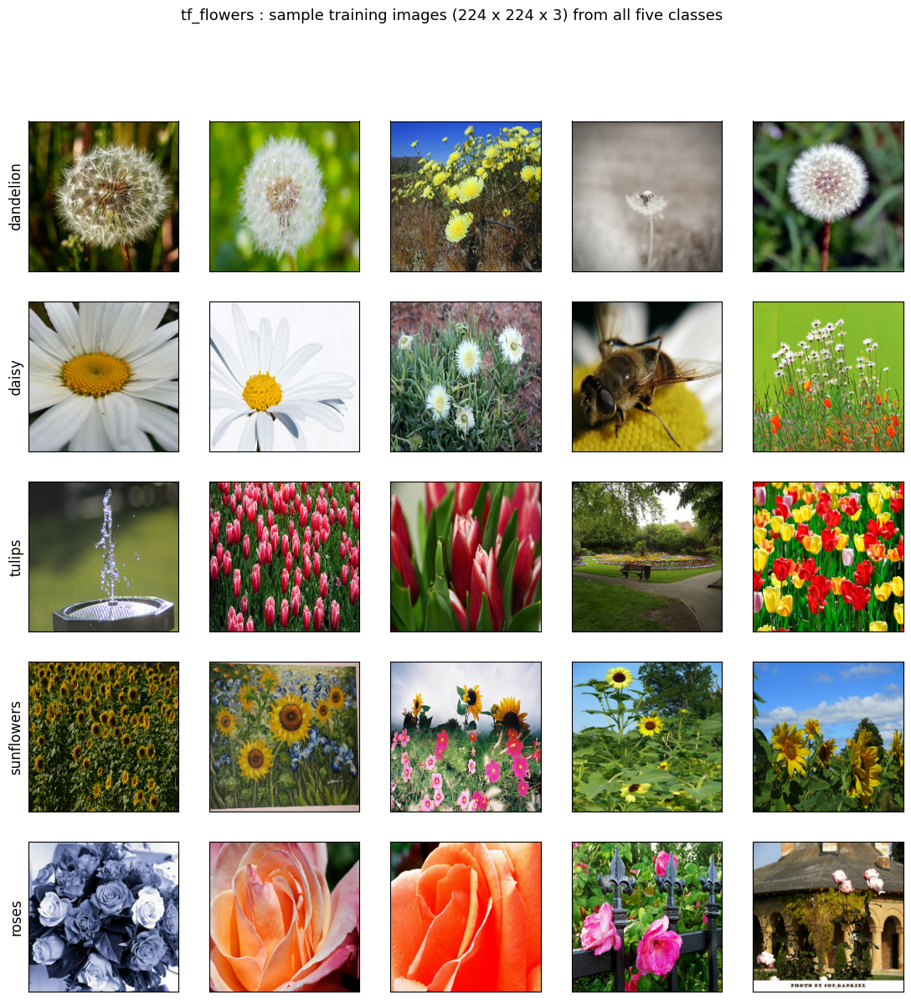

Saved figure -> outputs/figures/15_sample_images_all_classes.png


In [4]:
rng = np.random.RandomState(SEED)
N_PER_CLASS = 5
fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(2.7 * N_PER_CLASS, 2.7 * NUM_CLASSES))
for r, cname in enumerate(CLASS_NAMES):
    picks = rng.choice(np.where(y_train == r)[0], N_PER_CLASS, replace=False)
    for j, i in enumerate(picks):
        ax = axes[r, j]
        ax.imshow(X_train[i]); ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(cname, fontsize=12)
fig.suptitle('tf_flowers : sample training images (224 x 224 x 3) from all five classes', fontsize=13)
save_fig(fig, '15_sample_images_all_classes')

## 4. Pretrained ResNet50 Backbone and Stage-wise Feature Hierarchy

In [5]:
# ResNet50 is rebuilt layer-by-layer (identical to keras.applications.ResNet50, same layer names)
# so attention can be inserted between stages; ImageNet weights are copied layer-by-layer.
BN_EPS = 1.001e-5

def _bottleneck(x, filters, stride=1, conv_shortcut=True, name=''):
    if conv_shortcut:
        sc = layers.Conv2D(4 * filters, 1, strides=stride, name=name + '_0_conv')(x)
        sc = layers.BatchNormalization(epsilon=BN_EPS, name=name + '_0_bn')(sc)
    else:
        sc = x
    x = layers.Conv2D(filters, 1, strides=stride, name=name + '_1_conv')(x)
    x = layers.BatchNormalization(epsilon=BN_EPS, name=name + '_1_bn')(x)
    x = layers.Activation('relu', name=name + '_1_relu')(x)
    x = layers.Conv2D(filters, 3, padding='same', name=name + '_2_conv')(x)
    x = layers.BatchNormalization(epsilon=BN_EPS, name=name + '_2_bn')(x)
    x = layers.Activation('relu', name=name + '_2_relu')(x)
    x = layers.Conv2D(4 * filters, 1, name=name + '_3_conv')(x)
    x = layers.BatchNormalization(epsilon=BN_EPS, name=name + '_3_bn')(x)
    x = layers.Add(name=name + '_add')([sc, x])          # residual connection
    return layers.Activation('relu', name=name + '_out')(x)

STAGES = [('P1', 'conv2', 64, 3, 1), ('P2', 'conv3', 128, 4, 2),
          ('P3', 'conv4', 256, 6, 2), ('P4', 'conv5', 512, 3, 2)]

def resnet50_graph(inputs, hooks=None):
    """hooks: {position: fn(x, position) -> x} applied right after the corresponding stage."""
    hooks = hooks or {}
    x = layers.ZeroPadding2D(((3, 3), (3, 3)), name='conv1_pad')(inputs)
    x = layers.Conv2D(64, 7, strides=2, name='conv1_conv')(x)
    x = layers.BatchNormalization(epsilon=BN_EPS, name='conv1_bn')(x)
    x = layers.Activation('relu', name='conv1_relu')(x)
    x = layers.ZeroPadding2D(((1, 1), (1, 1)), name='pool1_pad')(x)
    x = layers.MaxPooling2D(3, strides=2, name='pool1_pool')(x)
    for pos, stage, filters, blocks, stride in STAGES:
        x = _bottleneck(x, filters, stride=stride, conv_shortcut=True, name=f'{stage}_block1')
        for b in range(2, blocks + 1):
            x = _bottleneck(x, filters, conv_shortcut=False, name=f'{stage}_block{b}')
        if pos in hooks:
            x = hooks[pos](x, pos)
    return x

_ref = keras.applications.ResNet50(include_top=False, weights='imagenet',
                                   input_shape=(IMG_SIZE, IMG_SIZE, 3))
IMAGENET_WEIGHTS = {l.name: l.get_weights() for l in _ref.layers if len(l.get_weights()) > 0}
BACKBONE_LAYER_NAMES = {l.name for l in _ref.layers}

def load_imagenet_weights(model):
    n = 0
    for l in model.layers:
        if l.name in IMAGENET_WEIGHTS:
            l.set_weights(IMAGENET_WEIGHTS[l.name])
            n += 1
    assert n == len(IMAGENET_WEIGHTS), f'Only {n}/{len(IMAGENET_WEIGHTS)} ImageNet layers matched'

_inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name='input_image')
_bb = keras.Model(_inp, resnet50_graph(_inp), name='resnet50_rebuilt')
load_imagenet_weights(_bb)
_x = X_test_pre[:4]
_diff = np.abs(_ref.predict(_x, verbose=0) - _bb.predict(_x, verbose=0)).max()
print(f'Rebuilt ResNet50 vs keras.applications.ResNet50 : max |difference| = {_diff:.3e}')
assert _diff < 1e-3, 'Rebuilt backbone does not match the reference ResNet50'
print(f'ResNet50 (no top) parameters: {_bb.count_params():,}')

stage_layers = [('Stem + MaxPool', 'pool1_pool', '-'), ('conv2_x', 'conv2_block3_out', 'P1'),
                ('conv3_x', 'conv3_block4_out', 'P2'), ('conv4_x', 'conv4_block6_out', 'P3'),
                ('conv5_x', 'conv5_block3_out', 'P4')]
rows, STAGE_DIMS = [], {}
for stage, lname, pos in stage_layers:
    H, W, C = _bb.get_layer(lname).output.shape[1:]
    rows.append({'ResNet50 Stage': stage, 'Output Layer': lname, 'Spatial Resolution': f'{H} x {W}',
                 'Channels': C, 'Candidate Position': pos})
    if pos != '-':
        STAGE_DIMS[pos] = (H, W, C)
stage_df = pd.DataFrame(rows)
display(stage_df)

del _ref, _bb, _inp
keras.backend.clear_session(); gc.collect()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


I0000 00:00:1791634713.438726     139 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Rebuilt ResNet50 vs keras.applications.ResNet50 : max |difference| = 0.000e+00
ResNet50 (no top) parameters: 23,587,712


,ResNet50 Stage,Output Layer,Spatial Resolution,Channels,Candidate Position
0,Stem + MaxPool,pool1_pool,56 x 56,64,-
1,conv2_x,conv2_block3_out,56 x 56,256,P1
2,conv3_x,conv3_block4_out,28 x 28,512,P2
3,conv4_x,conv4_block6_out,14 x 14,1024,P3
4,conv5_x,conv5_block3_out,7 x 7,2048,P4


0

## 5. Attention Modules (Channel, Spatial, Channel–Spatial, Self-Attention, ECA, CBAM, Coordinate)

In [6]:
# --------------------------------------------------------------------------
# Channel attention (Section 9) : Mc = sigmoid(W2 ReLU(W1 GAP(F))), Fc = F * Mc
# NOTE: this is exactly the Squeeze-and-Excitation (SE) formulation.
# --------------------------------------------------------------------------
def channel_attention(x, p, r=REDUCTION):
    C = x.shape[-1]
    z = layers.GlobalAveragePooling2D(name=f'{p}_ca_gap')(x)
    z = layers.Dense(max(C // r, 1), activation='relu', name=f'{p}_ca_fc1')(z)
    w = layers.Dense(C, activation='sigmoid', name=f'{p}_ca_weights')(z)
    w = layers.Reshape((1, 1, C), name=f'{p}_ca_reshape')(w)
    return layers.Multiply(name=f'{p}_ca_mul')([x, w])

# --------------------------------------------------------------------------
# Spatial attention (Section 10) : Ms = sigmoid(Conv_kxk([Mean_c(F) || Max_c(F)]))
# --------------------------------------------------------------------------
def spatial_attention(x, p, k=DEFAULT_KERNEL):
    avg = layers.Lambda(lambda t: ops.mean(t, axis=-1, keepdims=True), name=f'{p}_sa_avg')(x)
    mx = layers.Lambda(lambda t: ops.max(t, axis=-1, keepdims=True), name=f'{p}_sa_max')(x)
    s = layers.Concatenate(axis=-1, name=f'{p}_sa_concat')([avg, mx])
    m = layers.Conv2D(1, k, padding='same', activation='sigmoid', name=f'{p}_sa_map')(s)
    return layers.Multiply(name=f'{p}_sa_mul')([x, m])

# --------------------------------------------------------------------------
# Lightweight self-attention (Section 12) : F_SA = F + gamma * reshape(softmax(QK^T / sqrt(d)) V)
# Returns [output, attention matrix]; the matrix is only used for visualisation.
# --------------------------------------------------------------------------
class SelfAttention2D(layers.Layer):
    def __init__(self, channels, reduction=SA_REDUCTION, **kwargs):
        super().__init__(**kwargs)
        self.channels = int(channels)
        self.d = max(self.channels // reduction, 1)
        self.q_conv = layers.Conv2D(self.d, 1, name='query')
        self.k_conv = layers.Conv2D(self.d, 1, name='key')
        self.v_conv = layers.Conv2D(self.channels, 1, name='value')

    def build(self, input_shape):
        self.q_conv.build(input_shape)
        self.k_conv.build(input_shape)
        self.v_conv.build(input_shape)
        self.gamma = self.add_weight(name='gamma', shape=(), initializer='zeros', trainable=True)

    def call(self, x):
        h, w = x.shape[1], x.shape[2]
        n = h * w
        q = ops.reshape(self.q_conv(x), (-1, n, self.d))
        k = ops.reshape(self.k_conv(x), (-1, n, self.d))
        v = ops.reshape(self.v_conv(x), (-1, n, self.channels))
        attn = ops.softmax(ops.matmul(q, ops.transpose(k, (0, 2, 1))) / math.sqrt(self.d), axis=-1)
        y = ops.reshape(ops.matmul(attn, v), (-1, h, w, self.channels))
        return [x + self.gamma * y, attn]

    def compute_output_shape(self, input_shape):
        n = input_shape[1] * input_shape[2]
        return [tuple(input_shape), (input_shape[0], n, n)]

# --------------------------------------------------------------------------
# ECA (Wang et al., 2020) : 1D convolution over the channel descriptor, adaptive kernel size
# --------------------------------------------------------------------------
def eca_attention(x, p, gamma=2, b=1):
    C = x.shape[-1]
    t = int(abs((math.log2(C) + b) / gamma))
    k = t if t % 2 else t + 1
    z = layers.GlobalAveragePooling2D(name=f'{p}_eca_gap')(x)
    z = layers.Reshape((C, 1), name=f'{p}_eca_reshape1')(z)
    z = layers.Conv1D(1, k, padding='same', use_bias=False, name=f'{p}_eca_conv1d')(z)
    w = layers.Activation('sigmoid', name=f'{p}_eca_weights')(z)
    w = layers.Reshape((1, 1, C), name=f'{p}_eca_reshape2')(w)
    return layers.Multiply(name=f'{p}_eca_mul')([x, w])

# --------------------------------------------------------------------------
# CBAM (Woo et al., 2018) : channel attention with shared MLP on avg- AND max-pooled descriptors,
# followed by spatial attention
# --------------------------------------------------------------------------
def cbam_attention(x, p, r=REDUCTION, k=DEFAULT_KERNEL):
    C = x.shape[-1]
    fc1 = layers.Dense(max(C // r, 1), activation='relu', name=f'{p}_cbam_fc1')
    fc2 = layers.Dense(C, name=f'{p}_cbam_fc2')
    avg = layers.GlobalAveragePooling2D(name=f'{p}_cbam_gap')(x)
    mx = layers.GlobalMaxPooling2D(name=f'{p}_cbam_gmp')(x)
    s = layers.Add(name=f'{p}_cbam_add')([fc2(fc1(avg)), fc2(fc1(mx))])
    w = layers.Activation('sigmoid', name=f'{p}_cbam_ca_weights')(s)
    w = layers.Reshape((1, 1, C), name=f'{p}_cbam_ca_reshape')(w)
    xc = layers.Multiply(name=f'{p}_cbam_ca_mul')([x, w])
    return spatial_attention(xc, f'{p}_cbam', k)

# --------------------------------------------------------------------------
# Coordinate attention (Hou et al., 2021) : direction-aware pooling along H and W
# --------------------------------------------------------------------------
def h_swish(t):
    return t * ops.relu6(t + 3.0) / 6.0

def coordinate_attention(x, p, reduction=32):
    H, W, C = x.shape[1], x.shape[2], x.shape[3]
    mip = max(8, C // reduction)
    xh = layers.Lambda(lambda t: ops.mean(t, axis=2, keepdims=True), name=f'{p}_coord_pool_h')(x)
    xw = layers.Lambda(lambda t: ops.transpose(ops.mean(t, axis=1, keepdims=True), (0, 2, 1, 3)),
                       name=f'{p}_coord_pool_w')(x)
    y = layers.Concatenate(axis=1, name=f'{p}_coord_concat')([xh, xw])
    y = layers.Conv2D(mip, 1, name=f'{p}_coord_conv1')(y)
    y = layers.BatchNormalization(name=f'{p}_coord_bn')(y)
    y = layers.Lambda(h_swish, name=f'{p}_coord_hswish')(y)
    yh = layers.Lambda(lambda t, H=H: t[:, :H], name=f'{p}_coord_split_h')(y)
    yw = layers.Lambda(lambda t, H=H: ops.transpose(t[:, H:], (0, 2, 1, 3)), name=f'{p}_coord_split_w')(y)
    a_h = layers.Conv2D(C, 1, activation='sigmoid', name=f'{p}_coord_ah')(yh)
    a_w = layers.Conv2D(C, 1, activation='sigmoid', name=f'{p}_coord_aw')(yw)
    out = layers.Multiply(name=f'{p}_coord_mul_h')([x, a_h])
    return layers.Multiply(name=f'{p}_coord_mul_w')([out, a_w])

# --------------------------------------------------------------------------
# Attention hook inserted between ResNet50 stages: Previous stage -> Attention -> Next stage
# --------------------------------------------------------------------------
def build_attention_hook(att, k=DEFAULT_KERNEL):
    def hook(x, pos):
        p = f'att_{pos}'
        C = x.shape[-1]
        if att == 'channel':
            y = channel_attention(x, p)
        elif att == 'spatial':
            y = spatial_attention(x, p, k)
        elif att == 'cs':                       # Channel -> Spatial
            y = spatial_attention(channel_attention(x, p), p, k)
        elif att == 'sc':                       # Spatial -> Channel
            y = channel_attention(spatial_attention(x, p, k), p)
        elif att == 'sa':
            y, _ = SelfAttention2D(C, name=f'{p}_selfatt')(x)
        elif att == 'cs_sa':                    # Channel -> Spatial -> Self-attention
            y = spatial_attention(channel_attention(x, p), p, k)
            y, _ = SelfAttention2D(C, name=f'{p}_selfatt')(y)
        elif att == 'eca':
            y = eca_attention(x, p)
        elif att == 'cbam':
            y = cbam_attention(x, p, k=k)
        elif att == 'coord':
            y = coordinate_attention(x, p)
        else:
            raise ValueError(f'Unknown attention type: {att}')
        return layers.Identity(name=f'{p}_out')(y)
    return hook

# Parameters introduced by each module at every candidate position
MODULE_TYPES = {'channel': 'Channel (SE)', 'spatial': 'Spatial', 'cs': 'Channel->Spatial',
                'sc': 'Spatial->Channel', 'sa': 'Self-Attention', 'cs_sa': 'Combined C->S->SA',
                'eca': 'ECA', 'cbam': 'CBAM', 'coord': 'Coordinate'}
rows = []
for pos, (H, W, C) in STAGE_DIMS.items():
    for att, name in MODULE_TYPES.items():
        _i = keras.Input((H, W, C))
        _o = build_attention_hook(att)(_i, pos)
        _m = keras.Model(_i, _o)
        rows.append({'Position': pos, 'Resolution': f'{H}x{W}', 'Channels': C, 'Attention': name,
                     'Parameters': _m.count_params(), 'Input Shape': str((H, W, C)),
                     'Output Shape': str(tuple(_o.shape[1:]))})
module_params_df = pd.DataFrame(rows)
display(module_params_df.pivot(index='Attention', columns='Position', values='Parameters'))

# Size of the self-attention matrix (N x N, N = HW) at each position
sa_rows = []
for pos, (H, W, C) in STAGE_DIMS.items():
    N = H * W
    sa_rows.append({'Position': pos, 'Resolution': f'{H}x{W}', 'N = HW': N, 'Attention matrix': f'{N} x {N}',
                    'Elements': N * N, 'Memory per image (MB, float32)': N * N * 4 / 2**20})
sa_size_df = pd.DataFrame(sa_rows)
display(sa_size_df)

keras.backend.clear_session(); gc.collect()

Position,P1,P2,P3,P4
Attention,,,,
CBAM,8563,33411,132259,526563
Channel (SE),8464,33312,132160,526464
Channel->Spatial,8563,33411,132259,526563
Combined C->S->SA,90804,361732,1444260,5772004
Coordinate,6696,25680,100512,397632
ECA,5,5,5,7
Self-Attention,82241,328321,1312001,5245441
Spatial,99,99,99,99
Spatial->Channel,8563,33411,132259,526563


,Position,Resolution,N = HW,Attention matrix,Elements,"Memory per image (MB, float32)"
0,P1,56x56,3136,3136 x 3136,9834496,37.515625
1,P2,28x28,784,784 x 784,614656,2.344727
2,P3,14x14,196,196 x 196,38416,0.146545
3,P4,7x7,49,49 x 49,2401,0.009159


0

## 6. Model Builder, Training, Evaluation and Visualisation Utilities

In [7]:
# ------------------------------------------------------------------
# Experiment registry (unique trained models) and aliases (re-used runs)
# ------------------------------------------------------------------
CONFIGS = {
    'A0':     dict(label='Baseline ResNet50',             att='none',    positions=[]),
    'A1':     dict(label='Channel Attention @P3 (= SE)',  att='channel', positions=['P3']),
    'A2':     dict(label='Spatial Attention @P3',         att='spatial', positions=['P3'], k=7),
    'A3':     dict(label='Channel->Spatial @P3 (k=7)',    att='cs',      positions=['P3'], k=7),
    'A4':     dict(label='Self-Attention @P3',            att='sa',      positions=['P3']),
    'A5':     dict(label='Combined C->S->SA @P3',         att='cs_sa',   positions=['P3'], k=7),
    'B1':     dict(label='Channel->Spatial @P1',          att='cs',      positions=['P1'], k=7),
    'B2':     dict(label='Channel->Spatial @P2',          att='cs',      positions=['P2'], k=7),
    'B4':     dict(label='Channel->Spatial @P4',          att='cs',      positions=['P4'], k=7),
    'M_P34':  dict(label='Channel->Spatial @P3+P4',       att='cs',      positions=['P3', 'P4'], k=7),
    'M_P234': dict(label='Channel->Spatial @P2+P3+P4',    att='cs',      positions=['P2', 'P3', 'P4'], k=7),
    'O_SC':   dict(label='Spatial->Channel @P3',          att='sc',      positions=['P3'], k=7),
    'K3':     dict(label='Channel->Spatial @P3 (k=3)',    att='cs',      positions=['P3'], k=3),
    'K5':     dict(label='Channel->Spatial @P3 (k=5)',    att='cs',      positions=['P3'], k=5),
    'ECA':    dict(label='ECA @P3',                       att='eca',     positions=['P3']),
    'CBAM':   dict(label='CBAM @P3',                      att='cbam',    positions=['P3'], k=7),
    'COORD':  dict(label='Coordinate Attention @P3',      att='coord',   positions=['P3']),
}
ALIASES = {'B3': 'A3', 'M_P3': 'A3', 'M_P4': 'B4', 'O_CS': 'A3', 'K7': 'A3', 'SE': 'A1'}
def resolve(key):
    return ALIASES.get(key, key)

DISPLAY = {'A0': 'Baseline', 'A1': 'Channel', 'A2': 'Spatial', 'A3': 'Channel+Spatial', 'A4': 'Self-Attention',
           'A5': 'Combined (C+S+SA)', 'B1': 'C+S @P1', 'B2': 'C+S @P2', 'B3': 'C+S @P3', 'B4': 'C+S @P4',
           'M_P3': 'P3 only', 'M_P4': 'P4 only', 'M_P34': 'P3 + P4', 'M_P234': 'P2 + P3 + P4',
           'O_CS': 'Channel -> Spatial', 'O_SC': 'Spatial -> Channel', 'K3': 'k = 3', 'K5': 'k = 5', 'K7': 'k = 7',
           'SE': 'SE (Channel)', 'ECA': 'ECA', 'CBAM': 'CBAM', 'COORD': 'Coordinate'}
FULL_NAME = {k: v['label'] for k, v in CONFIGS.items()}

GROUPS = {
    'exp1_attention_type':     ['A0', 'A1', 'A2', 'A3', 'A4', 'A5'],
    'exp2_attention_position': ['A0', 'B1', 'B2', 'B3', 'B4'],
    'exp3_multiple_positions': ['A0', 'M_P3', 'M_P4', 'M_P34', 'M_P234'],
    'exp4_attention_order':    ['A0', 'O_CS', 'O_SC'],
    'exp5_spatial_kernel':     ['A0', 'K3', 'K5', 'K7'],
    'additional_mechanisms':   ['A0', 'SE', 'A2', 'ECA', 'CBAM', 'A4', 'COORD'],
}
GROUP_TITLES = {
    'exp1_attention_type': 'Experiment 1 : attention type (P3)',
    'exp2_attention_position': 'Experiment 2 : attention position (Channel->Spatial)',
    'exp3_multiple_positions': 'Experiment 3 : multiple attention positions',
    'exp4_attention_order': 'Experiment 4 : attention order (P3)',
    'exp5_spatial_kernel': 'Experiment 5 : spatial-attention kernel size (P3)',
    'additional_mechanisms': 'Additional task : attention mechanisms (P3)',
}

# ------------------------------------------------------------------
# Model builder : Input -> ResNet50 (+attention) -> GAP -> Dropout -> Dense(5)
# ------------------------------------------------------------------
def build_model(key, imagenet=True):
    cfg = CONFIGS[resolve(key)]
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3), name='input_image')
    hooks = {} if cfg['att'] == 'none' else {
        p: build_attention_hook(cfg['att'], cfg.get('k', DEFAULT_KERNEL)) for p in cfg['positions']}
    x = resnet50_graph(inp, hooks)
    x = layers.GlobalAveragePooling2D(name='head_gap')(x)
    x = layers.Dropout(DROPOUT, name='head_dropout')(x)
    x = layers.Dense(NUM_CLASSES, name='head_dense')(x)            # class scores (logits) y^c
    out = layers.Activation('softmax', name='head_softmax')(x)
    model = keras.Model(inp, out, name=resolve(key))
    if imagenet:
        load_imagenet_weights(model)
    return model

def set_phase(model, phase):
    """'head': whole ResNet50 frozen.  'ft': conv5_x conv layers trainable, BatchNorm stays frozen."""
    for l in model.layers:
        if l.name in BACKBONE_LAYER_NAMES:
            if phase == 'head':
                l.trainable = False
            else:
                l.trainable = l.name.startswith('conv5_') and not isinstance(l, layers.BatchNormalization)
        else:
            l.trainable = True

def count_trainable(model):
    return int(sum(np.prod(v.shape) for v in model.trainable_weights))

def count_attention_params(model):
    return int(sum(l.count_params() for l in model.layers if l.name.startswith('att_')))

class BestWeightsKeeper(keras.callbacks.Callback):
    def __init__(self, state, offset=0):
        super().__init__()
        self.state, self.offset = state, offset
    def on_epoch_end(self, epoch, logs=None):
        v = (logs or {}).get('val_accuracy', -1.0)
        if v > self.state['best_val_acc']:
            self.state.update(best_val_acc=float(v), best_epoch=epoch + 1 + self.offset,
                              weights=self.model.get_weights())

def reset_gpu_peak():
    try:
        tf.config.experimental.reset_memory_stats('GPU:0')
    except Exception:
        pass

def get_gpu_peak_mb():
    try:
        return tf.config.experimental.get_memory_info('GPU:0')['peak'] / 2**20
    except Exception:
        return np.nan

def measure_inference(model, n=INFER_N, warmup=INFER_WARMUP):
    """Average latency per image (batch size 1, GPU, compiled tf.function)."""
    infer = tf.function(lambda x: model(x, training=False), reduce_retracing=True)
    xs = X_test_pre[:n]
    for i in range(warmup):
        infer(tf.constant(xs[i:i + 1])).numpy()
    t = []
    for i in range(n):
        xi = tf.constant(xs[i:i + 1])
        t0 = time.perf_counter()
        infer(xi).numpy()
        t.append((time.perf_counter() - t0) * 1000.0)
    return float(np.mean(t)), float(np.std(t))

def compute_gflops(model):
    try:
        from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2
        fn = tf.function(lambda x: model(x, training=False))
        conc = fn.get_concrete_function(tf.TensorSpec([1, IMG_SIZE, IMG_SIZE, 3], tf.float32))
        frozen = convert_variables_to_constants_v2(conc)
        opts = (tf.compat.v1.profiler.ProfileOptionBuilder(
            tf.compat.v1.profiler.ProfileOptionBuilder.float_operation()).with_empty_output().build())
        prof = tf.compat.v1.profiler.profile(graph=frozen.graph, run_meta=tf.compat.v1.RunMetadata(),
                                             cmd='op', options=opts)
        return prof.total_float_ops / 1e9
    except Exception as e:
        print('GFLOPs could not be computed:', e)
        return np.nan

# ------------------------------------------------------------------
# Result storage (+ resume support if the kernel restarts)
# ------------------------------------------------------------------
RESULTS, HISTORIES, PROBS = {}, {}, {}
RESULTS_FILE = os.path.join(OUT_DIR, 'all_model_results.csv')
HIST_FILE = os.path.join(OUT_DIR, 'all_training_histories.csv')
PRED_FILE = os.path.join(OUT_DIR, 'all_test_predictions.csv')

def persist():
    pd.DataFrame([RESULTS[k] for k in CONFIGS if k in RESULTS]).to_csv(RESULTS_FILE, index=False)
    pd.concat([HISTORIES[k].assign(key=k) for k in CONFIGS if k in HISTORIES]).to_csv(HIST_FILE, index=False)
    pdf = pd.DataFrame({'tfds_index': idx_test, 'y_true': y_test, 'class_true': [CLASS_NAMES[i] for i in y_test]})
    for k in CONFIGS:
        if k in PROBS:
            pdf[f'pred_{k}'] = PROBS[k].argmax(1)
            for ci, c in enumerate(CLASS_NAMES):
                pdf[f'prob_{k}_{c}'] = PROBS[k][:, ci]
    pdf.to_csv(PRED_FILE, index=False)

def try_load_cached(key):
    w = os.path.join(CKPT_DIR, f'{key}.weights.h5')
    if not all(os.path.exists(f) for f in (w, RESULTS_FILE, HIST_FILE, PRED_FILE)):
        return False
    res = pd.read_csv(RESULTS_FILE)
    if key not in set(res['key']):
        return False
    preds_df = pd.read_csv(PRED_FILE)
    cols = [f'prob_{key}_{c}' for c in CLASS_NAMES]
    if not set(cols).issubset(preds_df.columns):
        return False
    hist = pd.read_csv(HIST_FILE)
    RESULTS[key] = res[res['key'] == key].iloc[0].to_dict()
    HISTORIES[key] = hist[hist['key'] == key].drop(columns='key').reset_index(drop=True)
    PROBS[key] = preds_df[cols].values
    print(f'[{key}] loaded from previous run (cache).')
    return True

def preds(key):
    return PROBS[resolve(key)].argmax(1)

# ------------------------------------------------------------------
# Train (2 phases) + evaluate one configuration
# ------------------------------------------------------------------
def run_experiment(key, force=False):
    key = resolve(key)
    if key in RESULTS and not force:
        print(f'[{key}] {FULL_NAME[key]} : already trained -> re-used.')
        return RESULTS[key]
    cfg = CONFIGS[key]
    print('=' * 90)
    print(f'[{key}] {cfg["label"]} | attention={cfg["att"]} | positions={cfg["positions"] or "-"}')
    print('=' * 90)
    keras.backend.clear_session(); gc.collect(); set_seed()
    train_ds, val_ds, test_ds = make_datasets()
    model = build_model(key)
    state = dict(best_val_acc=-1.0, best_epoch=0, weights=None)
    reset_gpu_peak()
    t0 = time.time()

    # Phase 1 : frozen ResNet50, train attention + classifier
    set_phase(model, 'head')
    trainable_p1 = count_trainable(model)
    model.compile(optimizer=keras.optimizers.Adam(LR_HEAD), loss='categorical_crossentropy', metrics=['accuracy'])
    print(f'Phase 1 (frozen backbone) trainable params: {trainable_p1:,}')
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_HEAD,
                   callbacks=[BestWeightsKeeper(state, 0)], verbose=2)

    # Phase 2 : fine-tune conv5_x with a smaller learning rate
    set_phase(model, 'ft')
    trainable_p2 = count_trainable(model)
    model.compile(optimizer=keras.optimizers.Adam(LR_FT), loss='categorical_crossentropy', metrics=['accuracy'])
    print(f'Phase 2 (conv5_x fine-tuning) trainable params: {trainable_p2:,}')
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT,
                   callbacks=[BestWeightsKeeper(state, EPOCHS_HEAD)], verbose=2)
    train_time = time.time() - t0
    peak_mem = get_gpu_peak_mb()

    hist = pd.DataFrame({m: h1.history[m] + h2.history[m] for m in ['accuracy', 'val_accuracy', 'loss', 'val_loss']})
    hist.insert(0, 'epoch', np.arange(1, len(hist) + 1))
    hist['phase'] = ['head'] * EPOCHS_HEAD + ['finetune'] * EPOCHS_FT

    # Evaluate the best-validation-accuracy weights on the test set
    model.set_weights(state['weights'])
    probs = model.predict(test_ds, verbose=0)
    y_pred = probs.argmax(1)
    acc = accuracy_score(y_test, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    pc, rc, fc, _ = precision_recall_fscore_support(y_test, y_pred, labels=list(range(NUM_CLASSES)),
                                                    average=None, zero_division=0)
    test_loss = float(-np.mean(np.log(probs[np.arange(len(y_test)), y_test] + 1e-12)))
    inf_ms, inf_std = measure_inference(model)
    gflops = compute_gflops(model)

    row = dict(key=key, model=cfg['label'], attention=cfg['att'],
               positions='+'.join(cfg['positions']) or '-',
               spatial_kernel=cfg.get('k', '-') if cfg['att'] in ('spatial', 'cs', 'sc', 'cs_sa', 'cbam') else '-',
               test_accuracy=acc, macro_precision=p, macro_recall=r, macro_f1=f, test_loss=test_loss,
               final_train_accuracy=hist['accuracy'].iloc[-1], final_val_accuracy=hist['val_accuracy'].iloc[-1],
               best_val_accuracy=state['best_val_acc'], best_epoch=state['best_epoch'],
               final_train_loss=hist['loss'].iloc[-1], final_val_loss=hist['val_loss'].iloc[-1],
               total_params=model.count_params(), trainable_params_phase1=trainable_p1,
               trainable_params_phase2=trainable_p2, attention_params=count_attention_params(model),
               inference_ms_per_image=inf_ms, inference_ms_std=inf_std, gflops=gflops,
               train_time_s=train_time, peak_train_gpu_mem_mb=peak_mem)
    for ci, c in enumerate(CLASS_NAMES):
        row[f'precision_{c}'], row[f'recall_{c}'], row[f'f1_{c}'] = pc[ci], rc[ci], fc[ci]

    RESULTS[key], HISTORIES[key], PROBS[key] = row, hist, probs
    model.save_weights(os.path.join(CKPT_DIR, f'{key}.weights.h5'))
    persist()
    print(f'[{key}] Test acc={acc:.4f} | macro P={p:.4f} R={r:.4f} F1={f:.4f} | '
          f'best val acc={state["best_val_acc"]:.4f} (epoch {state["best_epoch"]}) | '
          f'params={row["total_params"]:,} | {inf_ms:.2f} ms/img | train {train_time / 60:.1f} min')
    del model, train_ds, val_ds, test_ds, state
    keras.backend.clear_session(); gc.collect()
    return row

def metric_row(key, complexity=False, **extra):
    r = RESULTS[resolve(key)]
    d = dict(extra)
    d.update({'Accuracy': r['test_accuracy'], 'Precision': r['macro_precision'], 'Recall': r['macro_recall'],
              'Macro F1': r['macro_f1'], 'Total Params': int(r['total_params']),
              'Trainable Params': int(r['trainable_params_phase2']), 'Attention Params': int(r['attention_params']),
              'Inference Time (ms/img)': r['inference_ms_per_image']})
    if complexity:
        d.update({'GFLOPs': r['gflops'], 'Training Time (s)': r['train_time_s'],
                  'Peak Train GPU Mem (MB)': r['peak_train_gpu_mem_mb']})
    return d

# ------------------------------------------------------------------
# Visualisation utilities (trained models are re-loaded from _ckpt/)
# ------------------------------------------------------------------
MODEL_CACHE, SUBMODEL_CACHE = {}, {}

def get_model(key):
    key = resolve(key)
    if key not in MODEL_CACHE:
        m = build_model(key, imagenet=False)
        m.load_weights(os.path.join(CKPT_DIR, f'{key}.weights.h5'))
        MODEL_CACHE[key] = m
    return MODEL_CACHE[key]

def _tensor_of(m, name):
    if name.endswith(':attn'):
        return m.get_layer(name[:-5]).output[1]
    out = m.get_layer(name).output
    return out[0] if isinstance(out, (list, tuple)) else out

def get_outputs(key, names, x, chunk=25):
    m = get_model(key)
    ck = (resolve(key), tuple(names))
    if ck not in SUBMODEL_CACHE:
        SUBMODEL_CACHE[ck] = keras.Model(m.input, [_tensor_of(m, n) for n in names])
    sub = SUBMODEL_CACHE[ck]
    outs = [[] for _ in names]
    for s in range(0, len(x), chunk):
        res = sub(tf.convert_to_tensor(x[s:s + chunk], tf.float32), training=False)
        if not isinstance(res, (list, tuple)):
            res = [res]
        for j, t in enumerate(res):
            outs[j].append(ops.convert_to_numpy(t))
    return [np.concatenate(o, axis=0) for o in outs]

def gradcam_layer(key):
    names = {l.name for l in get_model(key).layers}
    return 'att_P4_out' if 'att_P4_out' in names else 'conv5_block3_out'

def gradcam(key, x, class_idx=None, chunk=25):
    """Grad-CAM w.r.t. the class score (logit) of the predicted (or given) class."""
    m = get_model(key)
    ck = ('gradcam', resolve(key))
    if ck not in SUBMODEL_CACHE:
        SUBMODEL_CACHE[ck] = keras.Model(m.input, [m.get_layer(gradcam_layer(key)).output,
                                                   m.get_layer('head_dense').output])
    gm = SUBMODEL_CACHE[ck]
    cams, cls = [], []
    for s in range(0, len(x), chunk):
        xb = tf.convert_to_tensor(x[s:s + chunk], tf.float32)
        with tf.GradientTape() as tape:
            conv, logits = gm(xb, training=False)
            if class_idx is None:
                ci = tf.argmax(logits, axis=1, output_type=tf.int32)
            else:
                ci = tf.constant(np.asarray(class_idx)[s:s + chunk], tf.int32)
            score = tf.reduce_sum(logits * tf.one_hot(ci, NUM_CLASSES))
        g = tape.gradient(score, conv)
        alpha = tf.reduce_mean(g, axis=(1, 2), keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(alpha * conv, axis=-1))
        cams.append(cam.numpy()); cls.append(ci.numpy())
    return np.concatenate(cams), np.concatenate(cls)

def norm01(m):
    m = np.asarray(m, dtype=np.float32)
    m = m - m.min()
    return m / (m.max() + 1e-8)

def upsample(m, size=IMG_SIZE):
    return tf.image.resize(np.asarray(m, np.float32)[..., None], (size, size), method='bilinear').numpy()[..., 0]

def clean_ax(ax):
    ax.set_xticks([]); ax.set_yticks([])

def show_img(ax, img, title=None, ylabel=None):
    ax.imshow(img); clean_ax(ax)
    if title: ax.set_title(title, fontsize=9)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9)

def show_map(fig, ax, m, title=None, cmap='viridis'):
    im = ax.imshow(m, cmap=cmap)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
    clean_ax(ax)
    if title: ax.set_title(title, fontsize=9)

def show_overlay(ax, img, heat, title=None, alpha=0.45, cmap='jet'):
    ax.imshow(img)
    ax.imshow(norm01(upsample(heat)), cmap=cmap, alpha=alpha, vmin=0, vmax=1)
    clean_ax(ax)
    if title: ax.set_title(title, fontsize=9)

def release_models():
    MODEL_CACHE.clear(); SUBMODEL_CACHE.clear()
    keras.backend.clear_session(); gc.collect()

# Load any models already trained in this session folder (resume after a kernel restart)
for _k in CONFIGS:
    try_load_cached(_k)
print(f'Unique models to train: {len(CONFIGS)} | already available: {len(RESULTS)}')

Unique models to train: 17 | already available: 0


## 7. Baseline Model (A0): Pretrained ResNet50 without Attention

In [8]:
run_experiment('A0')
baseline_df = pd.DataFrame([metric_row('A0', complexity=True, Model='A0: Baseline ResNet50', Position='-')])
display(baseline_df.round(4))

[A0] Baseline ResNet50 | attention=none | positions=-
Phase 1 (frozen backbone) trainable params: 10,245
Epoch 1/10
81/81 - 42s - 517ms/step - accuracy: 0.6905 - loss: 0.8402 - val_accuracy: 0.8582 - val_loss: 0.3860
Epoch 2/10
81/81 - 20s - 253ms/step - accuracy: 0.8544 - loss: 0.4344 - val_accuracy: 0.8818 - val_loss: 0.3324
Epoch 3/10
81/81 - 20s - 245ms/step - accuracy: 0.8758 - loss: 0.3463 - val_accuracy: 0.8982 - val_loss: 0.3043
Epoch 4/10
81/81 - 20s - 247ms/step - accuracy: 0.8902 - loss: 0.2888 - val_accuracy: 0.8982 - val_loss: 0.2796
Epoch 5/10
81/81 - 20s - 250ms/step - accuracy: 0.8992 - loss: 0.2731 - val_accuracy: 0.9055 - val_loss: 0.2913
Epoch 6/10
81/81 - 20s - 249ms/step - accuracy: 0.9097 - loss: 0.2505 - val_accuracy: 0.9091 - val_loss: 0.2780
Epoch 7/10
81/81 - 20s - 250ms/step - accuracy: 0.9194 - loss: 0.2284 - val_accuracy: 0.9109 - val_loss: 0.2672
Epoch 8/10
81/81 - 20s - 247ms/step - accuracy: 0.9253 - loss: 0.2160 - val_accuracy: 0.9145 - val_loss: 0.2752

I0000 00:00:1791635191.110352      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791635191.110539      49 single_machine.cc:376] Starting new session
I0000 00:00:1791635191.122211      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791635191.123794      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[A0] Test acc=0.9292 | macro P=0.9282 R=0.9274 F1=0.9277 | best val acc=0.9327 (epoch 17) | params=23,597,957 | 9.38 ms/img | train 7.6 min


,Model,Position,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img),GFLOPs,Training Time (s),Peak Train GPU Mem (MB)
0,A0: Baseline ResNet50,-,0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781,7.7512,453.33,3224.1089


## 8. Main Experiment 1: Attention-Type Ablation at P3 (A0–A5)

In [9]:
for k in ['A1', 'A2', 'A3', 'A4', 'A5']:
    run_experiment(k)

EXP1 = [('A0', 'A0: Baseline ResNet50', '–', '–', '–'),
        ('A1', 'A1: Channel Attention', '✓', '–', '–'),
        ('A2', 'A2: Spatial Attention', '–', '✓', '–'),
        ('A3', 'A3: Channel+Spatial', '✓', '✓', '–'),
        ('A4', 'A4: Self-Attention', '–', '–', '✓'),
        ('A5', 'A5: Combined Attention', '✓', '✓', '✓')]
exp1_df = pd.DataFrame([metric_row(k, Model=n, Position='-' if k == 'A0' else 'P3', Channel=c, Spatial=s,
                                   **{'Self-Attention': sa}) for k, n, c, s, sa in EXP1])
display(exp1_df.round(4))
save_csv(exp1_df, 'exp1_attention_type_ablation')

[A1] Channel Attention @P3 (= SE) | attention=channel | positions=['P3']
Phase 1 (frozen backbone) trainable params: 142,405
Epoch 1/10
81/81 - 40s - 491ms/step - accuracy: 0.6933 - loss: 0.7919 - val_accuracy: 0.8836 - val_loss: 0.3839
Epoch 2/10
81/81 - 20s - 251ms/step - accuracy: 0.8630 - loss: 0.3754 - val_accuracy: 0.8491 - val_loss: 0.4224
Epoch 3/10
81/81 - 20s - 252ms/step - accuracy: 0.8836 - loss: 0.3170 - val_accuracy: 0.8836 - val_loss: 0.3314
Epoch 4/10
81/81 - 20s - 251ms/step - accuracy: 0.9054 - loss: 0.2617 - val_accuracy: 0.9127 - val_loss: 0.2873
Epoch 5/10
81/81 - 20s - 250ms/step - accuracy: 0.9128 - loss: 0.2389 - val_accuracy: 0.9036 - val_loss: 0.2864
Epoch 6/10
81/81 - 20s - 250ms/step - accuracy: 0.9268 - loss: 0.2024 - val_accuracy: 0.9000 - val_loss: 0.2968
Epoch 7/10
81/81 - 20s - 249ms/step - accuracy: 0.9334 - loss: 0.1895 - val_accuracy: 0.9109 - val_loss: 0.2828
Epoch 8/10
81/81 - 20s - 248ms/step - accuracy: 0.9299 - loss: 0.1971 - val_accuracy: 0.905

I0000 00:00:1791635663.838510      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791635663.838663      49 single_machine.cc:376] Starting new session
I0000 00:00:1791635663.850098      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791635663.851686      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[A1] Test acc=0.9256 | macro P=0.9262 R=0.9223 F1=0.9237 | best val acc=0.9364 (epoch 20) | params=23,730,117 | 9.70 ms/img | train 7.5 min
[A2] Spatial Attention @P3 | attention=spatial | positions=['P3']
Phase 1 (frozen backbone) trainable params: 10,344
Epoch 1/10
81/81 - 40s - 489ms/step - accuracy: 0.3449 - loss: 1.4645 - val_accuracy: 0.8309 - val_loss: 0.4797
Epoch 2/10
81/81 - 21s - 259ms/step - accuracy: 0.8229 - loss: 0.4902 - val_accuracy: 0.8600 - val_loss: 0.3520
Epoch 3/10
81/81 - 20s - 251ms/step - accuracy: 0.8739 - loss: 0.3522 - val_accuracy: 0.8927 - val_loss: 0.2762
Epoch 4/10
81/81 - 20s - 251ms/step - accuracy: 0.9039 - loss: 0.2854 - val_accuracy: 0.9127 - val_loss: 0.2625
Epoch 5/10
81/81 - 21s - 254ms/step - accuracy: 0.8996 - loss: 0.2633 - val_accuracy: 0.9018 - val_loss: 0.2745
Epoch 6/10
81/81 - 20s - 249ms/step - accuracy: 0.9093 - loss: 0.2506 - val_accuracy: 0.8945 - val_loss: 0.2792
Epoch 7/10
81/81 - 20s - 251ms/step - accuracy: 0.9163 - loss: 0.2291 -

I0000 00:00:1791636137.501523      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791636137.501708      49 single_machine.cc:376] Starting new session
I0000 00:00:1791636137.513072      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791636137.514643      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[A2] Test acc=0.9310 | macro P=0.9336 R=0.9267 F1=0.9295 | best val acc=0.9291 (epoch 17) | params=23,598,056 | 9.72 ms/img | train 7.5 min
[A3] Channel->Spatial @P3 (k=7) | attention=cs | positions=['P3']
Phase 1 (frozen backbone) trainable params: 142,504
Epoch 1/10
81/81 - 40s - 496ms/step - accuracy: 0.6135 - loss: 0.9450 - val_accuracy: 0.8618 - val_loss: 0.3887
Epoch 2/10
81/81 - 20s - 250ms/step - accuracy: 0.8645 - loss: 0.3760 - val_accuracy: 0.8800 - val_loss: 0.3293
Epoch 3/10
81/81 - 20s - 250ms/step - accuracy: 0.8926 - loss: 0.2990 - val_accuracy: 0.9073 - val_loss: 0.2613
Epoch 4/10
81/81 - 20s - 246ms/step - accuracy: 0.9011 - loss: 0.2601 - val_accuracy: 0.9164 - val_loss: 0.2519
Epoch 5/10
81/81 - 20s - 249ms/step - accuracy: 0.9241 - loss: 0.2138 - val_accuracy: 0.9127 - val_loss: 0.2641
Epoch 6/10
81/81 - 20s - 246ms/step - accuracy: 0.9268 - loss: 0.2030 - val_accuracy: 0.9109 - val_loss: 0.2537
Epoch 7/10
81/81 - 20s - 247ms/step - accuracy: 0.9319 - loss: 0.1835 

...

I0000 00:00:1791637604.244282      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791637604.244520      49 single_machine.cc:376] Starting new session
I0000 00:00:1791637604.255984      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791637604.257593      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[A5] Test acc=0.9328 | macro P=0.9345 R=0.9282 F1=0.9308 | best val acc=0.9400 (epoch 12) | params=25,042,217 | 9.87 ms/img | train 7.8 min


,Model,Position,Channel,Spatial,Self-Attention,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img)
0,A0: Baseline ResNet50,-,–,–,–,0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781
1,A1: Channel Attention,P3,✓,–,–,0.9256,0.9262,0.9223,0.9237,23730117,15095877,132160,9.7017
2,A2: Spatial Attention,P3,–,✓,–,0.9310,0.9336,0.9267,0.9295,23598056,14963816,99,9.7189
3,A3: Channel+Spatial,P3,✓,✓,–,0.9328,0.9326,0.9296,0.9309,23730216,15095976,132259,9.8108
4,A4: Self-Attention,P3,–,–,✓,0.9002,0.8999,0.8972,0.8981,24909958,16275718,1312001,9.8933
5,A5: Combined Attention,P3,✓,✓,✓,0.9328,0.9345,0.9282,0.9308,25042217,16407977,1444260,9.8675


Saved table  -> outputs/exp1_attention_type_ablation.csv


'outputs/exp1_attention_type_ablation.csv'

## 9. Main Experiment 2: Attention-Position Ablation (B1–B4, Channel → Spatial)

In [10]:
for k in ['B1', 'B2', 'B3', 'B4']:      # B3 re-uses A3 (identical configuration)
    run_experiment(k)

rows = [metric_row('A0', Experiment='A0 (reference)', **{'Attention Position': '-', 'Resolution': '-', 'Channels': '-'})]
for k, p in zip(['B1', 'B2', 'B3', 'B4'], ['P1', 'P2', 'P3', 'P4']):
    H, W, C = STAGE_DIMS[p]
    rows.append(metric_row(k, Experiment=k, **{'Attention Position': f'After {POSITIONS[p][0]}_x ({p})',
                                               'Resolution': f'{H} x {W}', 'Channels': C}))
exp2_df = pd.DataFrame(rows)
display(exp2_df.round(4))
save_csv(exp2_df, 'exp2_attention_position_ablation')

[B1] Channel->Spatial @P1 | attention=cs | positions=['P1']
Phase 1 (frozen backbone) trainable params: 18,808
Epoch 1/10
81/81 - 45s - 560ms/step - accuracy: 0.5858 - loss: 1.0719 - val_accuracy: 0.7636 - val_loss: 0.6338
Epoch 2/10
81/81 - 21s - 262ms/step - accuracy: 0.7894 - loss: 0.5842 - val_accuracy: 0.8418 - val_loss: 0.4330
Epoch 3/10
81/81 - 21s - 257ms/step - accuracy: 0.8307 - loss: 0.4616 - val_accuracy: 0.8691 - val_loss: 0.3699
Epoch 4/10
81/81 - 21s - 262ms/step - accuracy: 0.8661 - loss: 0.3789 - val_accuracy: 0.8836 - val_loss: 0.3288
Epoch 5/10
81/81 - 21s - 265ms/step - accuracy: 0.8708 - loss: 0.3419 - val_accuracy: 0.8927 - val_loss: 0.2946
Epoch 6/10
81/81 - 21s - 265ms/step - accuracy: 0.8832 - loss: 0.3056 - val_accuracy: 0.8982 - val_loss: 0.2907
Epoch 7/10
81/81 - 21s - 260ms/step - accuracy: 0.9089 - loss: 0.2652 - val_accuracy: 0.9091 - val_loss: 0.2759
Epoch 8/10
81/81 - 21s - 257ms/step - accuracy: 0.9089 - loss: 0.2534 - val_accuracy: 0.9127 - val_loss: 

I0000 00:00:1791638100.472059      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791638100.472222      49 single_machine.cc:376] Starting new session
I0000 00:00:1791638100.483542      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791638100.485155      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[B1] Test acc=0.8984 | macro P=0.8971 R=0.8983 F1=0.8970 | best val acc=0.9236 (epoch 11) | params=23,606,520 | 9.62 ms/img | train 7.9 min
[B2] Channel->Spatial @P2 | attention=cs | positions=['P2']
Phase 1 (frozen backbone) trainable params: 43,656
Epoch 1/10
81/81 - 42s - 514ms/step - accuracy: 0.3297 - loss: 1.5557 - val_accuracy: 0.6291 - val_loss: 0.9351
Epoch 2/10
81/81 - 21s - 262ms/step - accuracy: 0.7419 - loss: 0.6792 - val_accuracy: 0.8473 - val_loss: 0.4353
Epoch 3/10
81/81 - 21s - 254ms/step - accuracy: 0.8459 - loss: 0.4196 - val_accuracy: 0.8745 - val_loss: 0.3294
Epoch 4/10
81/81 - 20s - 252ms/step - accuracy: 0.8723 - loss: 0.3518 - val_accuracy: 0.8855 - val_loss: 0.3054
Epoch 5/10
81/81 - 21s - 259ms/step - accuracy: 0.8898 - loss: 0.2944 - val_accuracy: 0.9073 - val_loss: 0.2716
Epoch 6/10
81/81 - 20s - 250ms/step - accuracy: 0.9019 - loss: 0.2656 - val_accuracy: 0.9018 - val_loss: 0.2660
Epoch 7/10
81/81 - 21s - 258ms/step - accuracy: 0.9124 - loss: 0.2318 - val_a

I0000 00:00:1791638584.131693      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791638584.131877      49 single_machine.cc:376] Starting new session
I0000 00:00:1791638584.143345      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791638584.144917      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[B2] Test acc=0.9238 | macro P=0.9222 R=0.9223 F1=0.9221 | best val acc=0.9255 (epoch 12) | params=23,631,368 | 9.63 ms/img | train 7.7 min
[A3] Channel->Spatial @P3 (k=7) : already trained -> re-used.
[B4] Channel->Spatial @P4 | attention=cs | positions=['P4']
Phase 1 (frozen backbone) trainable params: 536,808
Epoch 1/10
81/81 - 40s - 496ms/step - accuracy: 0.7528 - loss: 0.6846 - val_accuracy: 0.8945 - val_loss: 0.3074
Epoch 2/10
81/81 - 20s - 253ms/step - accuracy: 0.8891 - loss: 0.3028 - val_accuracy: 0.9036 - val_loss: 0.2928
Epoch 3/10
81/81 - 20s - 248ms/step - accuracy: 0.9132 - loss: 0.2308 - val_accuracy: 0.9073 - val_loss: 0.2700
Epoch 4/10
81/81 - 20s - 245ms/step - accuracy: 0.9338 - loss: 0.1719 - val_accuracy: 0.9036 - val_loss: 0.3006
Epoch 5/10
81/81 - 20s - 245ms/step - accuracy: 0.9494 - loss: 0.1375 - val_accuracy: 0.9200 - val_loss: 0.2837
Epoch 6/10
81/81 - 20s - 247ms/step - accuracy: 0.9587 - loss: 0.1197 - val_accuracy: 0.8964 - val_loss: 0.3603
Epoch 7/10
81/

I0000 00:00:1791639054.744796      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791639054.744995      49 single_machine.cc:376] Starting new session
I0000 00:00:1791639054.756223      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791639054.757811      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[B4] Test acc=0.9256 | macro P=0.9276 R=0.9225 F1=0.9246 | best val acc=0.9273 (epoch 20) | params=24,124,520 | 9.79 ms/img | train 7.4 min


,Experiment,Attention Position,Resolution,Channels,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img)
0,A0 (reference),-,-,-,0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781
1,B1,After conv2_x (P1),56 x 56,256,0.8984,0.8971,0.8983,0.8970,23606520,14972280,8563,9.6180
2,B2,After conv3_x (P2),28 x 28,512,0.9238,0.9222,0.9223,0.9221,23631368,14997128,33411,9.6341
3,B3,After conv4_x (P3),14 x 14,1024,0.9328,0.9326,0.9296,0.9309,23730216,15095976,132259,9.8108
4,B4,After conv5_x (P4),7 x 7,2048,0.9256,0.9276,0.9225,0.9246,24124520,15490280,526563,9.7950


Saved table  -> outputs/exp2_attention_position_ablation.csv


'outputs/exp2_attention_position_ablation.csv'

## 10. Main Experiment 3: Multiple Attention Positions (P3, P4, P3+P4, P2+P3+P4)

In [11]:
for k in ['M_P3', 'M_P4', 'M_P34', 'M_P234']:     # P3-only = A3, P4-only = B4 (re-used)
    run_experiment(k)

rows = [metric_row('A0', complexity=True, Configuration='No attention (reference)')]
for k, n in [('M_P3', 'Attention only at P3'), ('M_P4', 'Attention only at P4'),
             ('M_P34', 'Attention at P3 + P4'), ('M_P234', 'Attention at P2 + P3 + P4 (extended)')]:
    rows.append(metric_row(k, complexity=True, Configuration=n))
exp3_df = pd.DataFrame(rows)
display(exp3_df.round(4))
save_csv(exp3_df, 'exp3_multiple_attention_positions')

[A3] Channel->Spatial @P3 (k=7) : already trained -> re-used.
[B4] Channel->Spatial @P4 : already trained -> re-used.
[M_P34] Channel->Spatial @P3+P4 | attention=cs | positions=['P3', 'P4']
Phase 1 (frozen backbone) trainable params: 669,067
Epoch 1/10
81/81 - 43s - 533ms/step - accuracy: 0.7034 - loss: 0.7762 - val_accuracy: 0.8764 - val_loss: 0.3787
Epoch 2/10
81/81 - 20s - 248ms/step - accuracy: 0.8840 - loss: 0.3336 - val_accuracy: 0.8800 - val_loss: 0.3449
Epoch 3/10
81/81 - 20s - 247ms/step - accuracy: 0.9132 - loss: 0.2354 - val_accuracy: 0.8709 - val_loss: 0.3914
Epoch 4/10
81/81 - 21s - 255ms/step - accuracy: 0.9268 - loss: 0.2049 - val_accuracy: 0.8982 - val_loss: 0.3156
Epoch 5/10
81/81 - 20s - 249ms/step - accuracy: 0.9439 - loss: 0.1615 - val_accuracy: 0.9164 - val_loss: 0.2734
Epoch 6/10
81/81 - 20s - 249ms/step - accuracy: 0.9552 - loss: 0.1316 - val_accuracy: 0.9145 - val_loss: 0.3013
Epoch 7/10
81/81 - 20s - 246ms/step - accuracy: 0.9591 - loss: 0.1118 - val_accuracy: 

I0000 00:00:1791639536.142227      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791639536.142414      49 single_machine.cc:376] Starting new session
I0000 00:00:1791639536.153568      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791639536.155152      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[M_P34] Test acc=0.9111 | macro P=0.9129 R=0.9088 F1=0.9098 | best val acc=0.9345 (epoch 17) | params=24,256,779 | 9.64 ms/img | train 7.6 min
[M_P234] Channel->Spatial @P2+P3+P4 | attention=cs | positions=['P2', 'P3', 'P4']
Phase 1 (frozen backbone) trainable params: 702,478
Epoch 1/10
81/81 - 47s - 575ms/step - accuracy: 0.5045 - loss: 1.1505 - val_accuracy: 0.8200 - val_loss: 0.4939
Epoch 2/10
81/81 - 21s - 257ms/step - accuracy: 0.8326 - loss: 0.4556 - val_accuracy: 0.8364 - val_loss: 0.4753
Epoch 3/10
81/81 - 21s - 253ms/step - accuracy: 0.8821 - loss: 0.3245 - val_accuracy: 0.8691 - val_loss: 0.3864
Epoch 4/10
81/81 - 20s - 251ms/step - accuracy: 0.9050 - loss: 0.2571 - val_accuracy: 0.8855 - val_loss: 0.3287
Epoch 5/10
81/81 - 21s - 255ms/step - accuracy: 0.9354 - loss: 0.1891 - val_accuracy: 0.9000 - val_loss: 0.2786
Epoch 6/10
81/81 - 20s - 251ms/step - accuracy: 0.9420 - loss: 0.1609 - val_accuracy: 0.9055 - val_loss: 0.2752
Epoch 7/10
81/81 - 20s - 253ms/step - accuracy: 0.9

I0000 00:00:1791640031.552192      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791640031.552351      49 single_machine.cc:376] Starting new session
I0000 00:00:1791640031.563457      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791640031.565077      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[M_P234] Test acc=0.9129 | macro P=0.9088 R=0.9116 F1=0.9097 | best val acc=0.9236 (epoch 11) | params=24,290,190 | 9.74 ms/img | train 7.8 min


,Configuration,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img),GFLOPs,Training Time (s),Peak Train GPU Mem (MB)
0,No attention (reference),0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781,7.7512,453.3300,3224.1089
1,Attention only at P3,0.9328,0.9326,0.9296,0.9309,23730216,15095976,132259,9.8108,7.7523,461.1740,1849.0591
2,Attention only at P4,0.9256,0.9276,0.9225,0.9246,24124520,15490280,526563,9.7950,7.7527,446.4201,3044.0239
3,Attention at P3 + P4,0.9111,0.9129,0.9088,0.9098,24256779,15622539,658822,9.6374,7.7538,456.7861,3270.6895
4,Attention at P2 + P3 + P4 (extended),0.9129,0.9088,0.9116,0.9097,24290190,15655950,692233,9.7430,7.7556,469.5047,3831.0732


Saved table  -> outputs/exp3_multiple_attention_positions.csv


'outputs/exp3_multiple_attention_positions.csv'

## 11. Main Experiment 4: Attention Order (Channel → Spatial vs Spatial → Channel at P3)

In [12]:
for k in ['O_CS', 'O_SC']:       # O_CS re-uses A3
    run_experiment(k)

exp4_df = pd.DataFrame([metric_row('A0', Order='No attention (reference)', Position='-'),
                        metric_row('O_CS', Order='Channel -> Spatial (F -> Mc -> Ms)', Position='P3'),
                        metric_row('O_SC', Order='Spatial -> Channel (F -> Ms -> Mc)', Position='P3')])
display(exp4_df.round(4))
save_csv(exp4_df, 'exp4_attention_order')

[A3] Channel->Spatial @P3 (k=7) : already trained -> re-used.
[O_SC] Spatial->Channel @P3 | attention=sc | positions=['P3']
Phase 1 (frozen backbone) trainable params: 142,504
Epoch 1/10
81/81 - 40s - 498ms/step - accuracy: 0.2141 - loss: 1.6500 - val_accuracy: 0.1764 - val_loss: 1.6214
Epoch 2/10
81/81 - 20s - 251ms/step - accuracy: 0.5138 - loss: 1.1583 - val_accuracy: 0.8200 - val_loss: 0.5069
Epoch 3/10
81/81 - 20s - 252ms/step - accuracy: 0.8455 - loss: 0.4610 - val_accuracy: 0.8691 - val_loss: 0.3660
Epoch 4/10
81/81 - 20s - 250ms/step - accuracy: 0.8638 - loss: 0.3770 - val_accuracy: 0.8873 - val_loss: 0.3523
Epoch 5/10
81/81 - 20s - 253ms/step - accuracy: 0.8972 - loss: 0.3108 - val_accuracy: 0.8836 - val_loss: 0.3567
Epoch 6/10
81/81 - 20s - 247ms/step - accuracy: 0.8949 - loss: 0.2879 - val_accuracy: 0.8909 - val_loss: 0.3421
Epoch 7/10
81/81 - 20s - 249ms/step - accuracy: 0.9074 - loss: 0.2572 - val_accuracy: 0.8855 - val_loss: 0.3613
Epoch 8/10
81/81 - 21s - 254ms/step - ac

I0000 00:00:1791640508.751405      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791640508.751608      49 single_machine.cc:376] Starting new session
I0000 00:00:1791640508.763120      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791640508.764699      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[O_SC] Test acc=0.9310 | macro P=0.9304 R=0.9296 F1=0.9300 | best val acc=0.9255 (epoch 15) | params=23,730,216 | 9.89 ms/img | train 7.5 min


,Order,Position,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img)
0,No attention (reference),-,0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781
1,Channel -> Spatial (F -> Mc -> Ms),P3,0.9328,0.9326,0.9296,0.9309,23730216,15095976,132259,9.8108
2,Spatial -> Channel (F -> Ms -> Mc),P3,0.9310,0.9304,0.9296,0.9300,23730216,15095976,132259,9.8853


Saved table  -> outputs/exp4_attention_order.csv


'outputs/exp4_attention_order.csv'

## 12. Main Experiment 5: Spatial-Attention Kernel Size (k = 3, 5, 7)

In [13]:
for k in ['K3', 'K5', 'K7']:     # K7 re-uses A3
    run_experiment(k)

rows = []
for key, ks in [('K3', '3 x 3'), ('K5', '5 x 5'), ('K7', '7 x 7')]:
    r = RESULTS[resolve(key)]
    rows.append({'Spatial Kernel': ks, 'Accuracy': r['test_accuracy'], 'Macro F1': r['macro_f1'],
                 'Inference Time (ms/img)': r['inference_ms_per_image'], 'Precision': r['macro_precision'],
                 'Recall': r['macro_recall'], 'Attention Params': int(r['attention_params']),
                 'Total Params': int(r['total_params'])})
exp5_df = pd.DataFrame(rows)
display(exp5_df.round(4))
save_csv(exp5_df, 'exp5_spatial_kernel_size')

[K3] Channel->Spatial @P3 (k=3) | attention=cs | positions=['P3']
Phase 1 (frozen backbone) trainable params: 142,424
Epoch 1/10
81/81 - 40s - 499ms/step - accuracy: 0.4807 - loss: 1.2247 - val_accuracy: 0.7400 - val_loss: 0.7121
Epoch 2/10
81/81 - 21s - 255ms/step - accuracy: 0.8058 - loss: 0.5373 - val_accuracy: 0.8345 - val_loss: 0.4565
Epoch 3/10
81/81 - 20s - 251ms/step - accuracy: 0.8533 - loss: 0.3987 - val_accuracy: 0.8509 - val_loss: 0.4216
Epoch 4/10
81/81 - 20s - 246ms/step - accuracy: 0.8778 - loss: 0.3261 - val_accuracy: 0.8727 - val_loss: 0.3549
Epoch 5/10
81/81 - 21s - 255ms/step - accuracy: 0.8972 - loss: 0.2761 - val_accuracy: 0.8873 - val_loss: 0.3384
Epoch 6/10
81/81 - 20s - 250ms/step - accuracy: 0.9155 - loss: 0.2331 - val_accuracy: 0.8964 - val_loss: 0.3211
Epoch 7/10
81/81 - 20s - 250ms/step - accuracy: 0.9237 - loss: 0.2047 - val_accuracy: 0.9055 - val_loss: 0.3137
Epoch 8/10
81/81 - 20s - 248ms/step - accuracy: 0.9311 - loss: 0.1784 - val_accuracy: 0.8909 - val

I0000 00:00:1791640986.293662      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791640986.293849      49 single_machine.cc:376] Starting new session
I0000 00:00:1791640986.305419      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791640986.307009      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[K3] Test acc=0.9328 | macro P=0.9326 R=0.9296 F1=0.9309 | best val acc=0.9327 (epoch 19) | params=23,730,136 | 9.63 ms/img | train 7.5 min
[K5] Channel->Spatial @P3 (k=5) | attention=cs | positions=['P3']
Phase 1 (frozen backbone) trainable params: 142,456
Epoch 1/10
81/81 - 40s - 500ms/step - accuracy: 0.4301 - loss: 1.3146 - val_accuracy: 0.7818 - val_loss: 0.6085
Epoch 2/10
81/81 - 20s - 253ms/step - accuracy: 0.8252 - loss: 0.4833 - val_accuracy: 0.8691 - val_loss: 0.3682
Epoch 3/10
81/81 - 20s - 250ms/step - accuracy: 0.8727 - loss: 0.3468 - val_accuracy: 0.8873 - val_loss: 0.3342
Epoch 4/10
81/81 - 20s - 250ms/step - accuracy: 0.8972 - loss: 0.2880 - val_accuracy: 0.8945 - val_loss: 0.3307
Epoch 5/10
81/81 - 21s - 253ms/step - accuracy: 0.9140 - loss: 0.2346 - val_accuracy: 0.9073 - val_loss: 0.2926
Epoch 6/10
81/81 - 20s - 250ms/step - accuracy: 0.9183 - loss: 0.2201 - val_accuracy: 0.8818 - val_loss: 0.3398
Epoch 7/10
81/81 - 20s - 252ms/step - accuracy: 0.9257 - loss: 0.1987 

I0000 00:00:1791641467.360534      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791641467.360761      49 single_machine.cc:376] Starting new session
I0000 00:00:1791641467.372247      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791641467.373836      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[K5] Test acc=0.9274 | macro P=0.9261 R=0.9269 F1=0.9259 | best val acc=0.9273 (epoch 17) | params=23,730,168 | 9.73 ms/img | train 7.6 min
[A3] Channel->Spatial @P3 (k=7) : already trained -> re-used.


,Spatial Kernel,Accuracy,Macro F1,Inference Time (ms/img),Precision,Recall,Attention Params,Total Params
0,3 x 3,0.9328,0.9309,9.6340,0.9326,0.9296,132179,23730136
1,5 x 5,0.9274,0.9259,9.7296,0.9261,0.9269,132211,23730168
2,7 x 7,0.9328,0.9309,9.8108,0.9326,0.9296,132259,23730216


Saved table  -> outputs/exp5_spatial_kernel_size.csv


'outputs/exp5_spatial_kernel_size.csv'

## 13. Additional Task: Comparison with Established Attention Mechanisms (SE, ECA, CBAM, Coordinate Attention)

In [14]:
for k in ['SE', 'ECA', 'CBAM', 'COORD']:     # SE == channel attention of Section 9 -> re-uses A1
    run_experiment(k)

ADDITIONAL_ROWS = [('A0', 'No Attention'), ('SE', 'Channel / SE'), ('A2', 'Spatial Attention'),
                   ('ECA', 'ECA'), ('CBAM', 'CBAM'), ('A4', 'Self-Attention'),
                   ('COORD', 'Additional Mechanism : Coordinate Attention'),
                   ('A3', 'Channel+Spatial (laboratory module, reference)')]
add_df = pd.DataFrame([metric_row(k, complexity=True, Attention=n, Position='-' if k == 'A0' else 'P3')
                       for k, n in ADDITIONAL_ROWS])
display(add_df.round(4))
save_csv(add_df, 'additional_attention_comparison')

[A1] Channel Attention @P3 (= SE) : already trained -> re-used.
[ECA] ECA @P3 | attention=eca | positions=['P3']
Phase 1 (frozen backbone) trainable params: 10,250
Epoch 1/10
81/81 - 41s - 512ms/step - accuracy: 0.6637 - loss: 0.9112 - val_accuracy: 0.8473 - val_loss: 0.4425
Epoch 2/10
81/81 - 21s - 257ms/step - accuracy: 0.8322 - loss: 0.4705 - val_accuracy: 0.8800 - val_loss: 0.3372
Epoch 3/10
81/81 - 20s - 250ms/step - accuracy: 0.8727 - loss: 0.3690 - val_accuracy: 0.8764 - val_loss: 0.3232
Epoch 4/10
81/81 - 21s - 256ms/step - accuracy: 0.8918 - loss: 0.3117 - val_accuracy: 0.8836 - val_loss: 0.2978
Epoch 5/10
81/81 - 21s - 255ms/step - accuracy: 0.8996 - loss: 0.2794 - val_accuracy: 0.8909 - val_loss: 0.2989
Epoch 6/10
81/81 - 21s - 258ms/step - accuracy: 0.9148 - loss: 0.2514 - val_accuracy: 0.8945 - val_loss: 0.2988
Epoch 7/10
81/81 - 20s - 253ms/step - accuracy: 0.9148 - loss: 0.2330 - val_accuracy: 0.8982 - val_loss: 0.3104
Epoch 8/10
81/81 - 20s - 249ms/step - accuracy: 0.93

I0000 00:00:1791641951.123093      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791641951.123287      49 single_machine.cc:376] Starting new session
I0000 00:00:1791641951.134838      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791641951.136447      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[ECA] Test acc=0.9238 | macro P=0.9256 R=0.9187 F1=0.9214 | best val acc=0.9218 (epoch 14) | params=23,597,962 | 9.63 ms/img | train 7.6 min
[CBAM] CBAM @P3 | attention=cbam | positions=['P3']
Phase 1 (frozen backbone) trainable params: 142,504
Epoch 1/10
81/81 - 42s - 520ms/step - accuracy: 0.6329 - loss: 0.9261 - val_accuracy: 0.8382 - val_loss: 0.4389
Epoch 2/10
81/81 - 21s - 257ms/step - accuracy: 0.8451 - loss: 0.4212 - val_accuracy: 0.8691 - val_loss: 0.3514
Epoch 3/10
81/81 - 20s - 250ms/step - accuracy: 0.8727 - loss: 0.3530 - val_accuracy: 0.8891 - val_loss: 0.3113
Epoch 4/10
81/81 - 20s - 249ms/step - accuracy: 0.8867 - loss: 0.3142 - val_accuracy: 0.8945 - val_loss: 0.2941
Epoch 5/10
81/81 - 20s - 250ms/step - accuracy: 0.9023 - loss: 0.2696 - val_accuracy: 0.8927 - val_loss: 0.3158
Epoch 6/10
81/81 - 20s - 247ms/step - accuracy: 0.9101 - loss: 0.2531 - val_accuracy: 0.9055 - val_loss: 0.2962
Epoch 7/10
81/81 - 21s - 254ms/step - accuracy: 0.9163 - loss: 0.2343 - val_accurac

I0000 00:00:1791642432.753494      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791642432.753651      49 single_machine.cc:376] Starting new session
I0000 00:00:1791642432.765195      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791642432.766775      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[CBAM] Test acc=0.9201 | macro P=0.9199 R=0.9155 F1=0.9168 | best val acc=0.9236 (epoch 20) | params=23,730,216 | 9.80 ms/img | train 7.6 min
[COORD] Coordinate Attention @P3 | attention=coord | positions=['P3']
Phase 1 (frozen backbone) trainable params: 110,693
Epoch 1/10
81/81 - 42s - 516ms/step - accuracy: 0.6030 - loss: 0.9841 - val_accuracy: 0.8455 - val_loss: 0.4714
Epoch 2/10
81/81 - 20s - 253ms/step - accuracy: 0.8606 - loss: 0.3731 - val_accuracy: 0.8836 - val_loss: 0.3414
Epoch 3/10
81/81 - 20s - 246ms/step - accuracy: 0.8965 - loss: 0.2803 - val_accuracy: 0.8800 - val_loss: 0.4194
Epoch 4/10
81/81 - 20s - 252ms/step - accuracy: 0.9303 - loss: 0.2168 - val_accuracy: 0.8909 - val_loss: 0.3377
Epoch 5/10
81/81 - 20s - 248ms/step - accuracy: 0.9334 - loss: 0.1873 - val_accuracy: 0.9036 - val_loss: 0.3179
Epoch 6/10
81/81 - 20s - 252ms/step - accuracy: 0.9385 - loss: 0.1602 - val_accuracy: 0.9091 - val_loss: 0.3339
Epoch 7/10
81/81 - 21s - 255ms/step - accuracy: 0.9619 - loss: 0

I0000 00:00:1791642914.556288      49 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1791642914.556480      49 single_machine.cc:376] Starting new session
I0000 00:00:1791642914.568018      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791642914.569599      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


[COORD] Test acc=0.9310 | macro P=0.9300 R=0.9285 F1=0.9290 | best val acc=0.9327 (epoch 16) | params=23,698,469 | 9.68 ms/img | train 7.6 min


,Attention,Position,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img),GFLOPs,Training Time (s),Peak Train GPU Mem (MB)
0,No Attention,-,0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781,7.7512,453.3300,3224.1089
1,Channel / SE,P3,0.9256,0.9262,0.9223,0.9237,23730117,15095877,132160,9.7017,7.7519,450.4294,1399.7300
2,Spatial Attention,P3,0.9310,0.9336,0.9267,0.9295,23598056,14963816,99,9.7189,7.7517,451.3174,1618.4622
3,ECA,P3,0.9238,0.9256,0.9187,0.9214,23597962,14963722,5,9.6293,7.7516,456.2696,4395.6152
4,CBAM,P3,0.9201,0.9199,0.9155,0.9168,23730216,15095976,132259,9.7981,7.7526,454.1397,4608.2219
5,Self-Attention,P3,0.9002,0.8999,0.8972,0.8981,24909958,16275718,1312001,9.8933,8.3544,469.2926,4213.1616
6,Additional Mechanism : Coordinate Attention,P3,0.9310,0.9300,0.9285,0.9290,23698469,15064165,100512,9.6798,7.7557,454.3517,4834.2295
7,"Channel+Spatial (laboratory module, reference)",P3,0.9328,0.9326,0.9296,0.9309,23730216,15095976,132259,9.8108,7.7523,461.1740,1849.0591


Saved table  -> outputs/additional_attention_comparison.csv


'outputs/additional_attention_comparison.csv'

## 14. Feature Dimensions Before and After Each Attention Module

In [15]:
release_models()
rows = []
for key, cfg in CONFIGS.items():
    if cfg['att'] == 'none':
        continue
    m = build_model(key, imagenet=False)
    for pos in cfg['positions']:
        before = tuple(m.get_layer(POSITIONS[pos][1]).output.shape[1:])
        after = tuple(m.get_layer(f'att_{pos}_out').output.shape[1:])
        nxt = {'P1': 'conv3_block1', 'P2': 'conv4_block1', 'P3': 'conv5_block1', 'P4': 'head_gap (GAP)'}[pos]
        rows.append({'Model': key, 'Description': cfg['label'], 'Position': pos,
                     'Placement': f'{POSITIONS[pos][0]}_x -> Attention -> {nxt}',
                     'Input to attention (H, W, C)': str(before), 'Output of attention (H, W, C)': str(after),
                     'Dimensions preserved': before == after})
    del m
    keras.backend.clear_session(); gc.collect()
dims_df = pd.DataFrame(rows)
display(dims_df)
save_csv(dims_df, 'attention_feature_dimensions')
assert dims_df['Dimensions preserved'].all(), 'An attention module changed the feature dimensions!'

,Model,Description,Position,Placement,"Input to attention (H, W, C)","Output of attention (H, W, C)",Dimensions preserved
0,A1,Channel Attention @P3 (= SE),P3,conv4_x -> Attention -> conv5_block1,"(14, 14, 1024)","(14, 14, 1024)",True
1,A2,Spatial Attention @P3,P3,conv4_x -> Attention -> conv5_block1,"(14, 14, 1024)","(14, 14, 1024)",True
2,A3,Channel->Spatial @P3 (k=7),P3,conv4_x -> Attention -> conv5_block1,"(14, 14, 1024)","(14, 14, 1024)",True
3,A4,Self-Attention @P3,P3,conv4_x -> Attention -> conv5_block1,"(14, 14, 1024)","(14, 14, 1024)",True
4,A5,Combined C->S->SA @P3,P3,conv4_x -> Attention -> conv5_block1,"(14, 14, 1024)","(14, 14, 1024)",True
5,B1,Channel->Spatial @P1,P1,conv2_x -> Attention -> conv3_block1,"(56, 56, 256)","(56, 56, 256)",True
6,B2,Channel->Spatial @P2,P2,conv3_x -> Attention -> conv4_block1,"(28, 28, 512)","(28, 28, 512)",True
7,B4,Channel->Spatial @P4,P4,conv5_x -> Attention -> head_gap (GAP),"(7, 7, 2048)","(7, 7, 2048)",True
8,M_P34,Channel->Spatial @P3+P4,P3,conv4_x -> Attention -> conv5_block1,"(14, 14, 1024)","(14, 14, 1024)",True
9,M_P34,Channel->Spatial @P3+P4,P4,conv5_x -> Attention -> head_gap (GAP),"(7, 7, 2048)","(7, 7, 2048)",True


Saved table  -> outputs/attention_feature_dimensions.csv


## 15. Required Main Result Table and Observation Summary

In [16]:
MAIN_ROWS = [('A0', 'Baseline', '-'), ('A1', 'Channel Attention', 'P3'), ('A2', 'Spatial Attention', 'P3'),
             ('B2', 'Channel+Spatial', 'P2'), ('A3', 'Channel+Spatial', 'P3'), ('B4', 'Channel+Spatial', 'P4'),
             ('A4', 'Self-Attention', 'P3'), ('ECA', 'Additional Attention-1 (ECA)', 'P3'),
             ('CBAM', 'Additional Attention-2 (CBAM)', 'P3'), ('COORD', 'Additional Attention-3 (Coordinate)', 'P3'),
             ('B1', 'Channel+Spatial (extra)', 'P1'), ('A5', 'Combined C+S+SA (extra)', 'P3')]
main_df = pd.DataFrame([metric_row(k, Model=n, Position=p) for k, n, p in MAIN_ROWS])
print('Required main result table (Section 23):')
display(main_df.round(4))
save_csv(main_df, 'main_results_table')

# Section 38 : observations to be recorded (all values are also in all_model_results.csv)
obs_cols = ['key', 'model', 'positions', 'final_train_accuracy', 'final_val_accuracy', 'best_val_accuracy',
            'test_accuracy', 'final_train_loss', 'final_val_loss', 'macro_precision', 'macro_recall', 'macro_f1',
            'trainable_params_phase2', 'total_params', 'attention_params', 'inference_ms_per_image']
display(pd.DataFrame([RESULTS[k] for k in CONFIGS])[obs_cols].round(4))
print('Re-used runs:', ALIASES)

Required main result table (Section 23):


,Model,Position,Accuracy,Precision,Recall,Macro F1,Total Params,Trainable Params,Attention Params,Inference Time (ms/img)
0,Baseline,-,0.9292,0.9282,0.9274,0.9277,23597957,14963717,0,9.3781
1,Channel Attention,P3,0.9256,0.9262,0.9223,0.9237,23730117,15095877,132160,9.7017
2,Spatial Attention,P3,0.9310,0.9336,0.9267,0.9295,23598056,14963816,99,9.7189
3,Channel+Spatial,P2,0.9238,0.9222,0.9223,0.9221,23631368,14997128,33411,9.6341
4,Channel+Spatial,P3,0.9328,0.9326,0.9296,0.9309,23730216,15095976,132259,9.8108
5,Channel+Spatial,P4,0.9256,0.9276,0.9225,0.9246,24124520,15490280,526563,9.7950
6,Self-Attention,P3,0.9002,0.8999,0.8972,0.8981,24909958,16275718,1312001,9.8933
7,Additional Attention-1 (ECA),P3,0.9238,0.9256,0.9187,0.9214,23597962,14963722,5,9.6293
8,Additional Attention-2 (CBAM),P3,0.9201,0.9199,0.9155,0.9168,23730216,15095976,132259,9.7981
9,Additional Attention-3 (Coordinate),P3,0.9310,0.9300,0.9285,0.9290,23698469,15064165,100512,9.6798


Saved table  -> outputs/main_results_table.csv


,key,model,positions,final_train_accuracy,final_val_accuracy,best_val_accuracy,test_accuracy,final_train_loss,final_val_loss,macro_precision,macro_recall,macro_f1,trainable_params_phase2,total_params,attention_params,inference_ms_per_image
0,A0,Baseline ResNet50,-,0.9938,0.9291,0.9327,0.9292,0.0276,0.3087,0.9282,0.9274,0.9277,14963717,23597957,0,9.3781
1,A1,Channel Attention @P3 (= SE),P3,0.9926,0.9364,0.9364,0.9256,0.0255,0.2623,0.9262,0.9223,0.9237,15095877,23730117,132160,9.7017
2,A2,Spatial Attention @P3,P3,0.9895,0.9236,0.9291,0.9310,0.0290,0.2983,0.9336,0.9267,0.9295,14963816,23598056,99,9.7189
3,A3,Channel->Spatial @P3 (k=7),P3,0.9957,0.9273,0.9400,0.9328,0.0188,0.3311,0.9326,0.9296,0.9309,15095976,23730216,132259,9.8108
4,A4,Self-Attention @P3,P3,0.9922,0.9291,0.9382,0.9002,0.0228,0.2617,0.8999,0.8972,0.8981,16275718,24909958,1312001,9.8933
5,A5,Combined C->S->SA @P3,P3,0.9907,0.9345,0.9400,0.9328,0.0284,0.2698,0.9345,0.9282,0.9308,16407977,25042217,1444260,9.8675
6,B1,Channel->Spatial @P1,P1,0.9895,0.9218,0.9236,0.8984,0.0330,0.3080,0.8971,0.8983,0.8970,14972280,23606520,8563,9.6180
7,B2,Channel->Spatial @P2,P2,0.9914,0.9182,0.9255,0.9238,0.0301,0.3027,0.9222,0.9223,0.9221,14997128,23631368,33411,9.6341
8,B4,Channel->Spatial @P4,P4,0.9953,0.9273,0.9273,0.9256,0.0113,0.3554,0.9276,0.9225,0.9246,15490280,24124520,526563,9.7950
9,M_P34,Channel->Spatial @P3+P4,P3+P4,0.9969,0.9036,0.9345,0.9111,0.0100,0.5361,0.9129,0.9088,0.9098,15622539,24256779,658822,9.6374


Re-used runs: {'B3': 'A3', 'M_P3': 'A3', 'M_P4': 'B4', 'O_CS': 'A3', 'K7': 'A3', 'SE': 'A1'}


## 16. Training and Validation Accuracy Curves

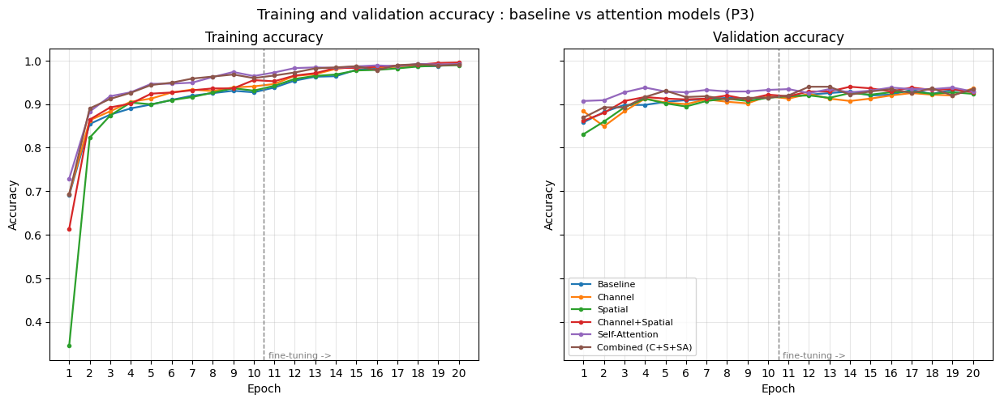

Saved figure -> outputs/figures/01_accuracy_curves_baseline_vs_attention.png


In [17]:
def plot_curves(keys, metric, fname, title):
    pal = sns.color_palette('tab10', len(keys))
    fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
    for ax, split in zip(axes, ['Training', 'Validation']):
        col = metric if split == 'Training' else f'val_{metric}'
        for c, k in zip(pal, keys):
            h = HISTORIES[resolve(k)]
            ax.plot(h['epoch'], h[col], marker='o', ms=3, lw=1.6, color=c, label=DISPLAY[k])
        ax.axvline(EPOCHS_HEAD + 0.5, color='grey', ls='--', lw=1)
        ax.text(EPOCHS_HEAD + 0.7, ax.get_ylim()[0], 'fine-tuning ->', color='grey', fontsize=8, va='bottom')
        ax.set_xticks(range(1, EPOCHS_TOTAL + 1))
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Accuracy' if metric == 'accuracy' else 'Categorical cross-entropy loss')
        ax.set_title(f'{split} {"accuracy" if metric == "accuracy" else "loss"}')
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=8)
    fig.suptitle(title, fontsize=13)
    save_fig(fig, fname)

# Plot 1 : epoch vs accuracy (baseline + attention models of Experiment 1)
plot_curves(GROUPS['exp1_attention_type'], 'accuracy', '01_accuracy_curves_baseline_vs_attention',
            'Training and validation accuracy : baseline vs attention models (P3)')

## 17. Training and Validation Loss Curves

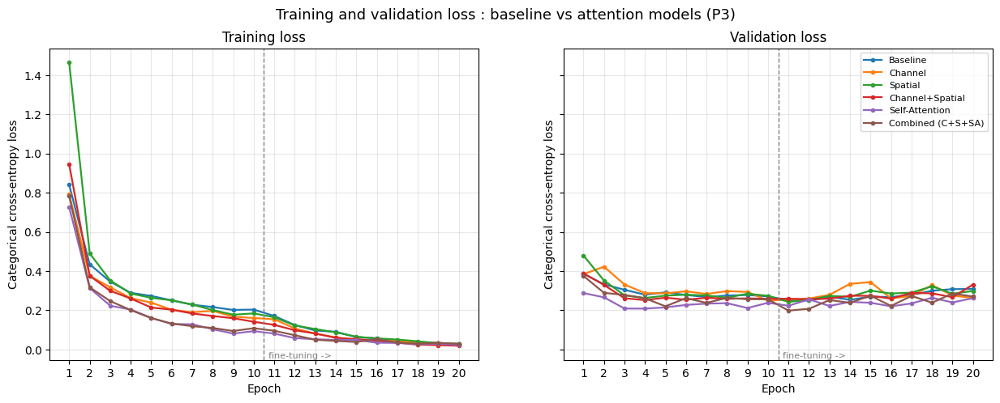

Saved figure -> outputs/figures/02_loss_curves_baseline_vs_attention.png


In [18]:
# Plot 2 : epoch vs categorical cross-entropy loss
plot_curves(GROUPS['exp1_attention_type'], 'loss', '02_loss_curves_baseline_vs_attention',
            'Training and validation loss : baseline vs attention models (P3)')

## 18. Graphical Performance Analysis (Accuracy, Macro F1, Accuracy–Complexity, F1–Inference Time)

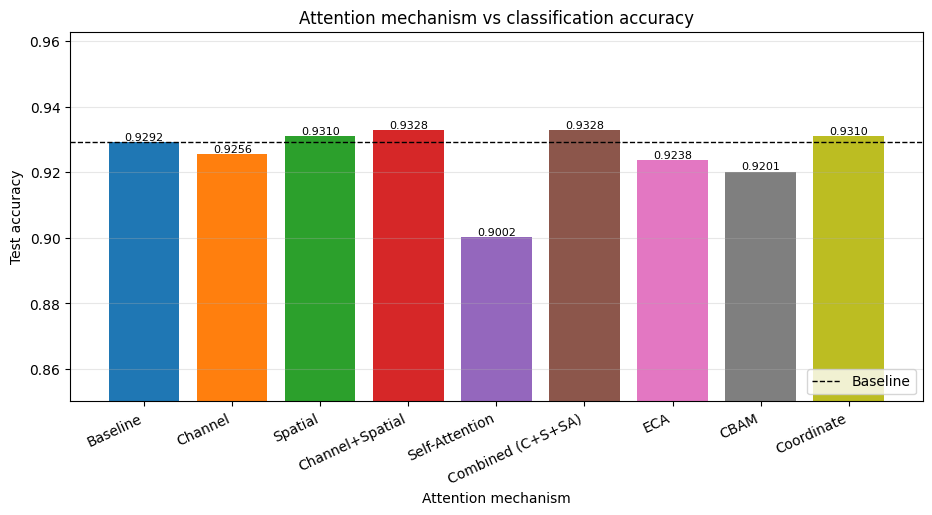

Saved figure -> outputs/figures/03_attention_mechanism_vs_accuracy.png


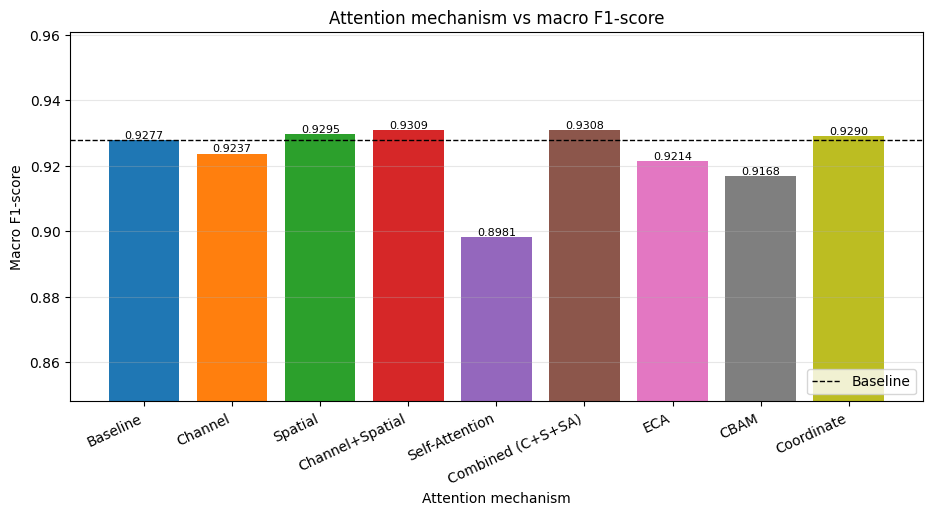

Saved figure -> outputs/figures/04_attention_mechanism_vs_macro_f1.png


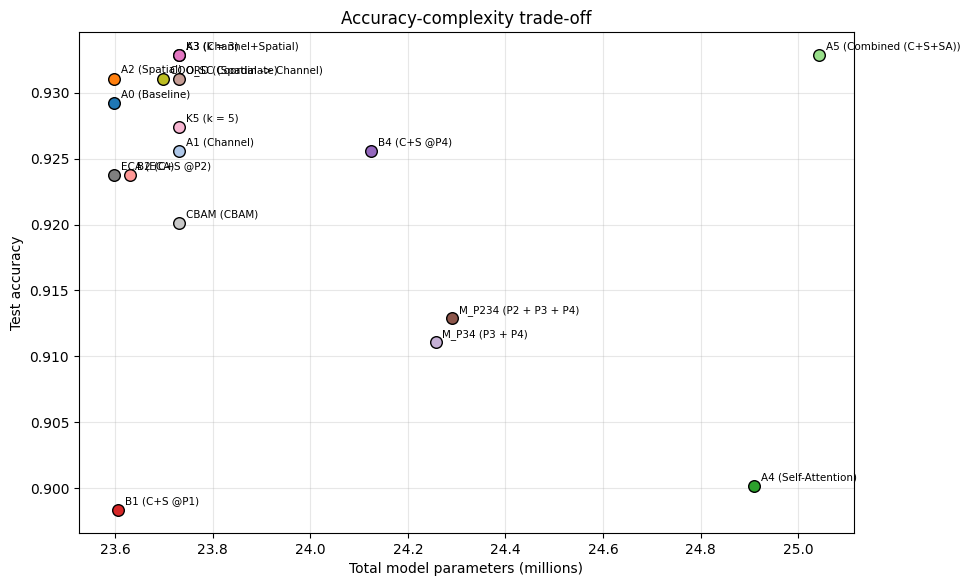

Saved figure -> outputs/figures/05_accuracy_vs_parameters.png


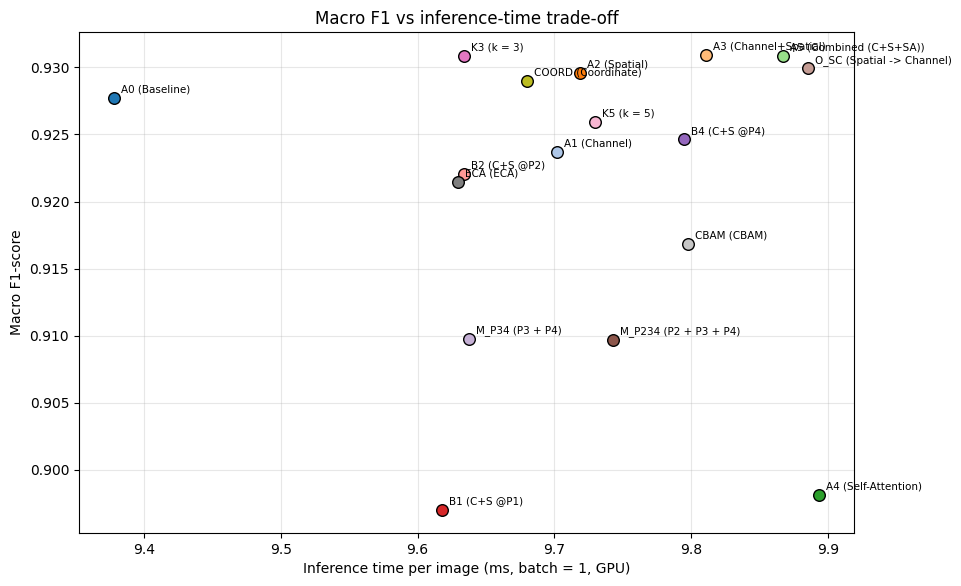

Saved figure -> outputs/figures/06_macro_f1_vs_inference_time.png


In [19]:
def R(k, m):
    return RESULTS[resolve(k)][m]

def bar_metric(ax, keys, metric, ylabel, zoom=True, fmt='%.4f'):
    vals = [R(k, metric) for k in keys]
    bars = ax.bar([DISPLAY[k] for k in keys], vals, color=sns.color_palette('tab10', len(keys)))
    ax.bar_label(bars, fmt=fmt, fontsize=8)
    if zoom:
        ax.axhline(R('A0', metric), color='k', ls='--', lw=1, label='Baseline')
        ax.set_ylim(max(0, min(vals) - 0.05), min(1.0, max(vals) + 0.03))
        ax.legend(loc='lower right')
    ax.set_ylabel(ylabel)
    plt.setp(ax.get_xticklabels(), rotation=25, ha='right')
    ax.grid(axis='y', alpha=0.3)

MECH = ['A0', 'A1', 'A2', 'A3', 'A4', 'A5', 'ECA', 'CBAM', 'COORD']

# Plot 3 : attention mechanism vs accuracy
fig, ax = plt.subplots(figsize=(11, 4.8))
bar_metric(ax, MECH, 'test_accuracy', 'Test accuracy')
ax.set_xlabel('Attention mechanism'); ax.set_title('Attention mechanism vs classification accuracy')
save_fig(fig, '03_attention_mechanism_vs_accuracy')

# Plot 4 : attention mechanism vs macro F1
fig, ax = plt.subplots(figsize=(11, 4.8))
bar_metric(ax, MECH, 'macro_f1', 'Macro F1-score')
ax.set_xlabel('Attention mechanism'); ax.set_title('Attention mechanism vs macro F1-score')
save_fig(fig, '04_attention_mechanism_vs_macro_f1')

# Plots 5 and 6 : accuracy vs parameters, macro F1 vs inference time
allk = list(CONFIGS)
for xm, ym, xl, yl, fname, ttl in [
        ('total_params', 'test_accuracy', 'Total model parameters (millions)', 'Test accuracy',
         '05_accuracy_vs_parameters', 'Accuracy-complexity trade-off'),
        ('inference_ms_per_image', 'macro_f1', 'Inference time per image (ms, batch = 1, GPU)', 'Macro F1-score',
         '06_macro_f1_vs_inference_time', 'Macro F1 vs inference-time trade-off')]:
    fig, ax = plt.subplots(figsize=(10, 6.5))
    pal = sns.color_palette('tab20', len(allk))
    for c, k in zip(pal, allk):
        xv = R(k, xm) / 1e6 if xm == 'total_params' else R(k, xm)
        ax.scatter(xv, R(k, ym), s=70, color=c, edgecolor='k', zorder=3)
        ax.annotate(f'{k} ({DISPLAY[k]})', (xv, R(k, ym)), textcoords='offset points', xytext=(5, 4), fontsize=7.5)
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.set_title(ttl); ax.grid(alpha=0.3)
    save_fig(fig, fname)

## 19. Confusion Matrix Analysis

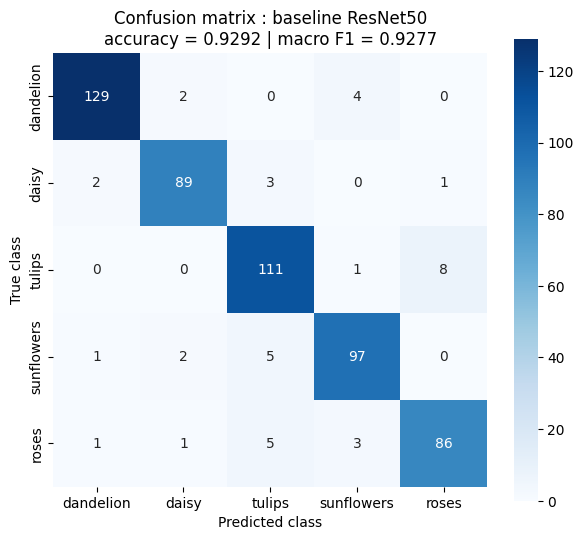

Saved figure -> outputs/figures/07_confusion_matrix_baseline.png


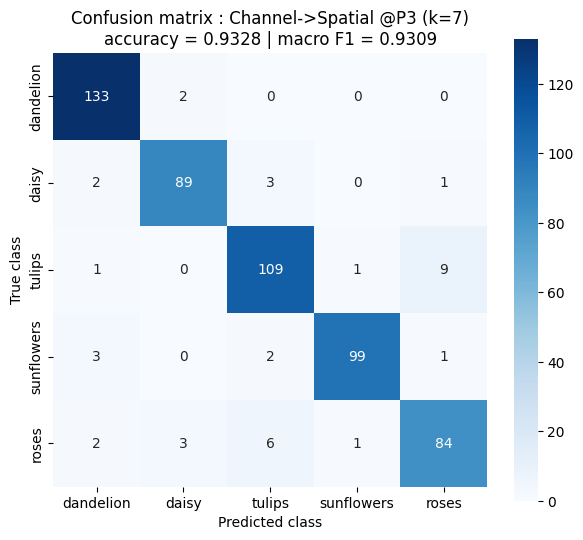

Saved figure -> outputs/figures/08_confusion_matrix_attention_A3.png
Saved table  -> outputs/confusion_matrices.csv


,dandelion,daisy,tulips,sunflowers,roses
Baseline F1,0.9627,0.9418,0.9098,0.9238,0.9005
A3 F1,0.9638,0.9418,0.9083,0.9612,0.8796
Change,0.0011,0.0000,-0.0015,0.0374,-0.0209


In [20]:
def cm_of(key):
    return confusion_matrix(y_test, preds(key), labels=list(range(NUM_CLASSES)))

def plot_cm(key, fname, title):
    cm = cm_of(key)
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=ax, square=True)
    ax.set_xlabel('Predicted class'); ax.set_ylabel('True class')
    ax.set_title(f'{title}\naccuracy = {R(key, "test_accuracy"):.4f} | macro F1 = {R(key, "macro_f1"):.4f}')
    save_fig(fig, fname)

SELECTED = 'A3'     # selected attention model : Channel+Spatial at P3
plot_cm('A0', '07_confusion_matrix_baseline', 'Confusion matrix : baseline ResNet50')                       # Plot 7
plot_cm(SELECTED, '08_confusion_matrix_attention_A3', f'Confusion matrix : {FULL_NAME[SELECTED]}')        # Plot 8

cm_rows = []
for k in CONFIGS:
    cm = cm_of(k)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            cm_rows.append({'key': k, 'true_class': CLASS_NAMES[i], 'predicted_class': CLASS_NAMES[j], 'count': int(cm[i, j])})
save_csv(pd.DataFrame(cm_rows), 'confusion_matrices')

cls_df = pd.DataFrame({c: [R(k, f'f1_{c}') for k in ['A0', SELECTED]] for c in CLASS_NAMES},
                      index=['Baseline F1', 'A3 F1'])
cls_df.loc['Change'] = cls_df.loc['A3 F1'] - cls_df.loc['Baseline F1']
display(cls_df.round(4))

## 20. Feature Maps Before and After Attention

Representative test images: [(107, 'dandelion'), (190, 'daisy'), (332, 'tulips'), (369, 'sunflowers'), (541, 'roses')]


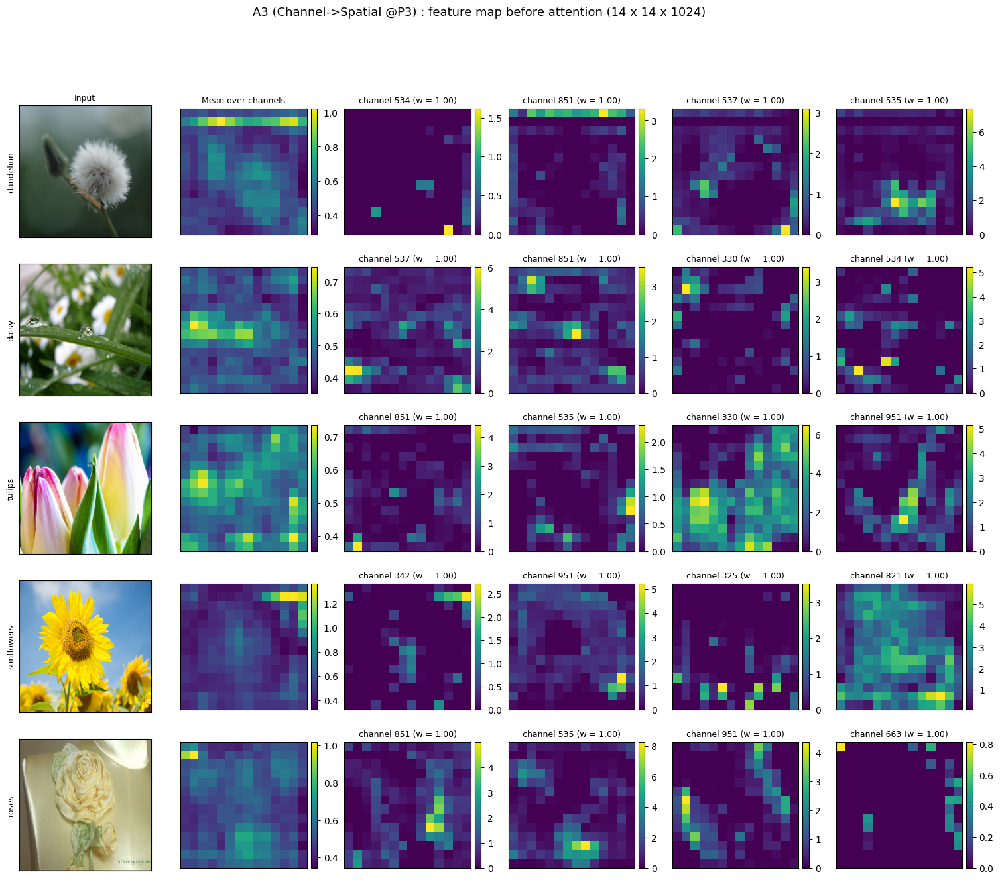

Saved figure -> outputs/figures/16_feature_map_before_attention.png


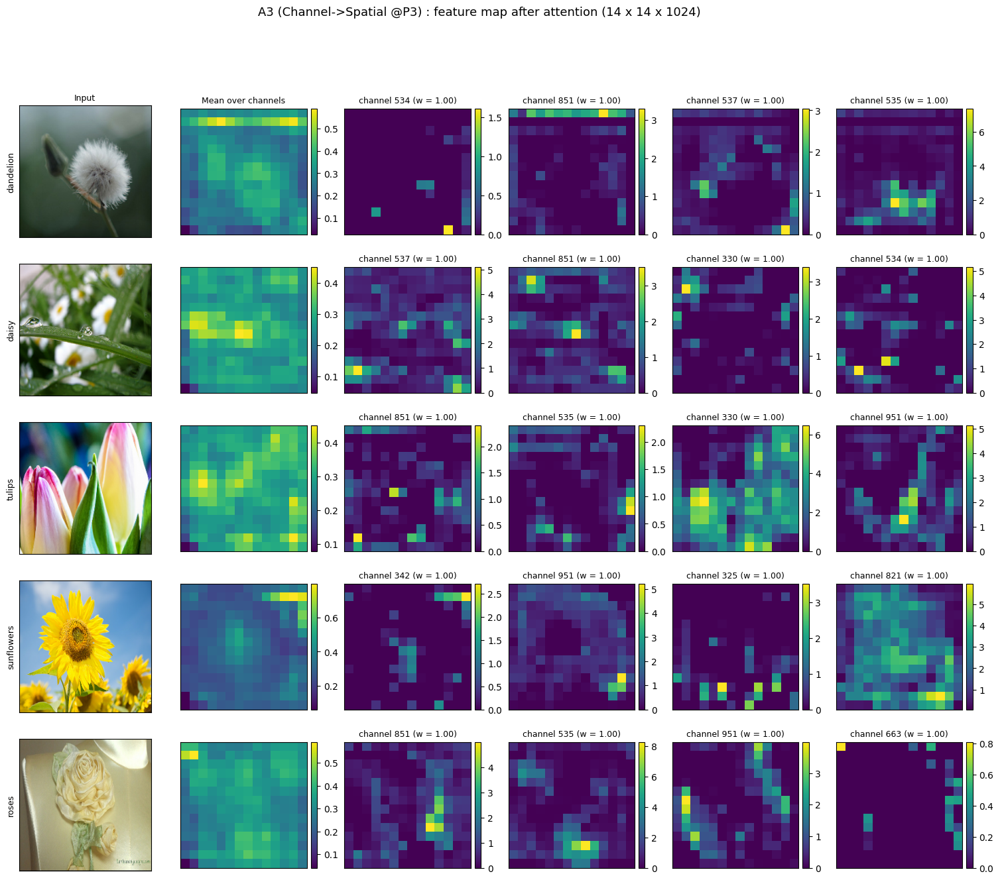

Saved figure -> outputs/figures/17_feature_map_after_attention.png


In [21]:
# Representative test images (one per class, correctly classified by baseline and A3, fixed seed)
pA0, pA3 = preds('A0'), preds('A3')
rng = np.random.RandomState(SEED)
VIS_IDX = []
for c in range(NUM_CLASSES):
    cand = np.where((y_test == c) & (pA0 == c) & (pA3 == c))[0]
    if len(cand) == 0:
        cand = np.where(y_test == c)[0]
    VIS_IDX.append(int(rng.choice(cand)))
X_vis, I_vis = X_test_pre[VIS_IDX], X_test[VIS_IDX]
print('Representative test images:', [(i, CLASS_NAMES[y_test[i]]) for i in VIS_IDX])

before, after, w = get_outputs('A3', ['conv4_block6_out', 'att_P3_out', 'att_P3_ca_weights'], X_vis)
N_CH = 4
for feat, tag, fname in [(before, 'before', '16_feature_map_before_attention'),
                         (after, 'after', '17_feature_map_after_attention')]:
    fig, axes = plt.subplots(len(VIS_IDX), 2 + N_CH, figsize=(3.1 * (2 + N_CH), 3.0 * len(VIS_IDX)))
    for r in range(len(VIS_IDX)):
        top = np.argsort(w[r])[::-1][:N_CH]          # channels with the largest attention weights
        show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
        show_map(fig, axes[r, 1], feat[r].mean(-1), 'Mean over channels' if r == 0 else None)
        for j, ch in enumerate(top):
            show_map(fig, axes[r, 2 + j], feat[r][..., ch], f'channel {ch} (w = {w[r][ch]:.2f})')
    fig.suptitle(f'A3 (Channel->Spatial @P3) : feature map {tag} attention (14 x 14 x 1024)', fontsize=13)
    save_fig(fig, fname)                                                                          # Plots 16, 17

## 21. Channel-Attention Weights

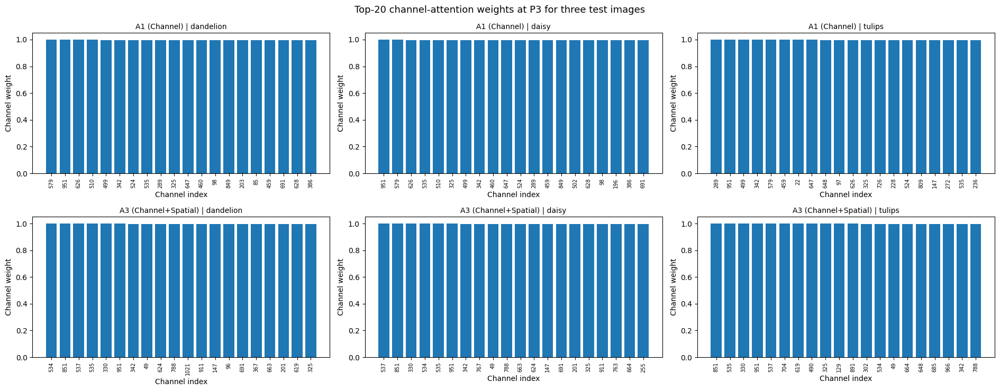

Saved figure -> outputs/figures/10_channel_attention_weights_top20.png


In [22]:
CH_LAYERS = {'A1': 'att_P3_ca_weights', 'A3': 'att_P3_ca_weights'}
fig, axes = plt.subplots(2, 3, figsize=(19, 7.5))
for r, k in enumerate(['A1', 'A3']):
    W = get_outputs(k, [CH_LAYERS[k]], X_vis[:3])[0].reshape(3, -1)
    for c in range(3):
        top = np.argsort(W[c])[::-1][:TOPK_CHANNELS]
        ax = axes[r, c]
        ax.bar([str(t) for t in top], W[c][top], color='tab:blue')
        ax.set_ylim(0, 1.05); ax.tick_params(axis='x', labelrotation=90, labelsize=7)
        ax.set_xlabel('Channel index'); ax.set_ylabel('Channel weight')
        ax.set_title(f'{k} ({DISPLAY[k]}) | {CLASS_NAMES[y_test[VIS_IDX[c]]]}', fontsize=10)
fig.suptitle(f'Top-{TOPK_CHANNELS} channel-attention weights at P3 for three test images', fontsize=13)
fig.tight_layout()
save_fig(fig, '10_channel_attention_weights_top20')                                              # Plot 10

## 22. Spatial-Attention Heatmaps and Overlays

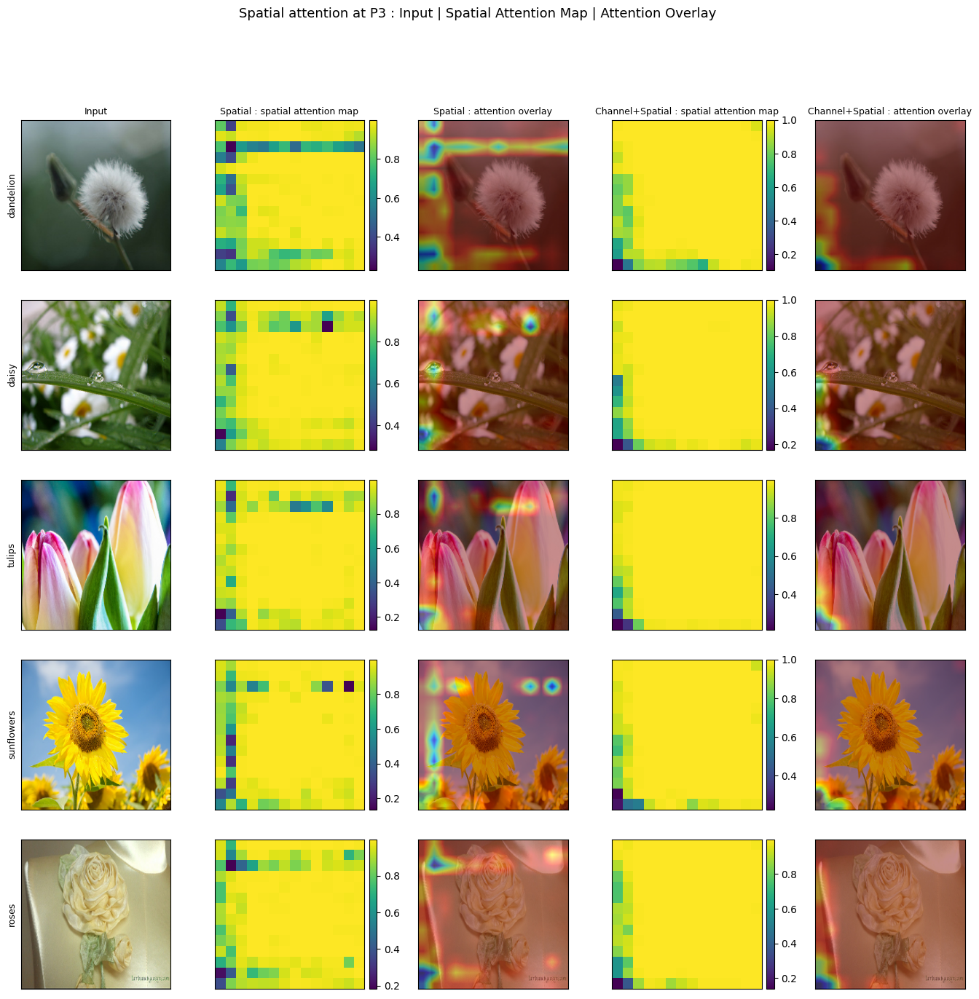

Saved figure -> outputs/figures/11_spatial_attention_map_overlay.png


In [23]:
def spatial_map(key, x, layer='att_P3_sa_map'):
    return get_outputs(key, [layer], x)[0][..., 0]

maps = {k: spatial_map(k, X_vis) for k in ['A2', 'A3']}
fig, axes = plt.subplots(len(VIS_IDX), 5, figsize=(17, 3.1 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    for j, k in enumerate(['A2', 'A3']):
        show_map(fig, axes[r, 1 + 2 * j], maps[k][r], f'{DISPLAY[k]} : spatial attention map' if r == 0 else None)
        show_overlay(axes[r, 2 + 2 * j], I_vis[r], maps[k][r], f'{DISPLAY[k]} : attention overlay' if r == 0 else None)
fig.suptitle('Spatial attention at P3 : Input | Spatial Attention Map | Attention Overlay', fontsize=13)
save_fig(fig, '11_spatial_attention_map_overlay')                                                # Plot 11

## 23. Self-Attention Response Visualisation

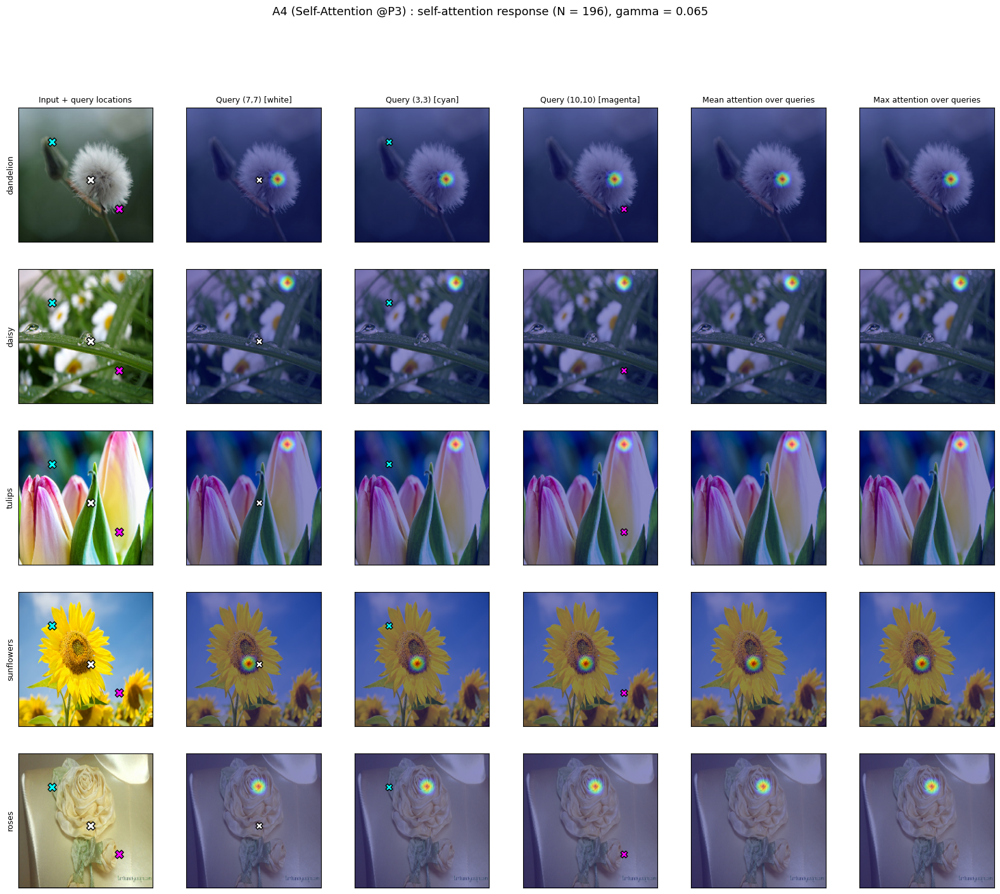

Saved figure -> outputs/figures/12_self_attention_response.png


In [24]:
Hs, Ws = STAGE_DIMS['P3'][:2]
QUERIES = [(Hs // 2, Ws // 2), (Hs // 4, Ws // 4), (3 * Hs // 4, 3 * Ws // 4)]
QCOL = ['white', 'cyan', 'magenta']
gamma_a4 = float(np.asarray(get_model('A4').get_layer('att_P3_selfatt').gamma.numpy()))

def sa_matrix(key, x):
    return get_outputs(key, ['att_P3_selfatt:attn'], x)[0]       # (B, N, N)

A = sa_matrix('A4', X_vis)
fig, axes = plt.subplots(len(VIS_IDX), 6, figsize=(20, 3.2 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    a = A[r]
    show_img(axes[r, 0], I_vis[r], 'Input + query locations' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    for (qy, qx), c in zip(QUERIES, QCOL):
        axes[r, 0].scatter((qx + 0.5) * IMG_SIZE / Ws, (qy + 0.5) * IMG_SIZE / Hs, s=90, c=c, marker='X', edgecolors='k')
    for j, ((qy, qx), c) in enumerate(zip(QUERIES, QCOL)):
        show_overlay(axes[r, j + 1], I_vis[r], a[qy * Ws + qx].reshape(Hs, Ws), f'Query ({qy},{qx}) [{c}]' if r == 0 else None)
        axes[r, j + 1].scatter((qx + 0.5) * IMG_SIZE / Ws, (qy + 0.5) * IMG_SIZE / Hs, s=60, c=c, marker='X', edgecolors='k')
    show_overlay(axes[r, 4], I_vis[r], a.mean(0).reshape(Hs, Ws), 'Mean attention over queries' if r == 0 else None)
    show_overlay(axes[r, 5], I_vis[r], a.max(0).reshape(Hs, Ws), 'Max attention over queries' if r == 0 else None)
fig.suptitle(f'A4 (Self-Attention @P3) : self-attention response (N = {Hs * Ws}), gamma = {gamma_a4:.3f}', fontsize=13)
save_fig(fig, '12_self_attention_response')                                                      # Plot 12

## 24. Grad-CAM Comparison: Baseline vs Attention Model

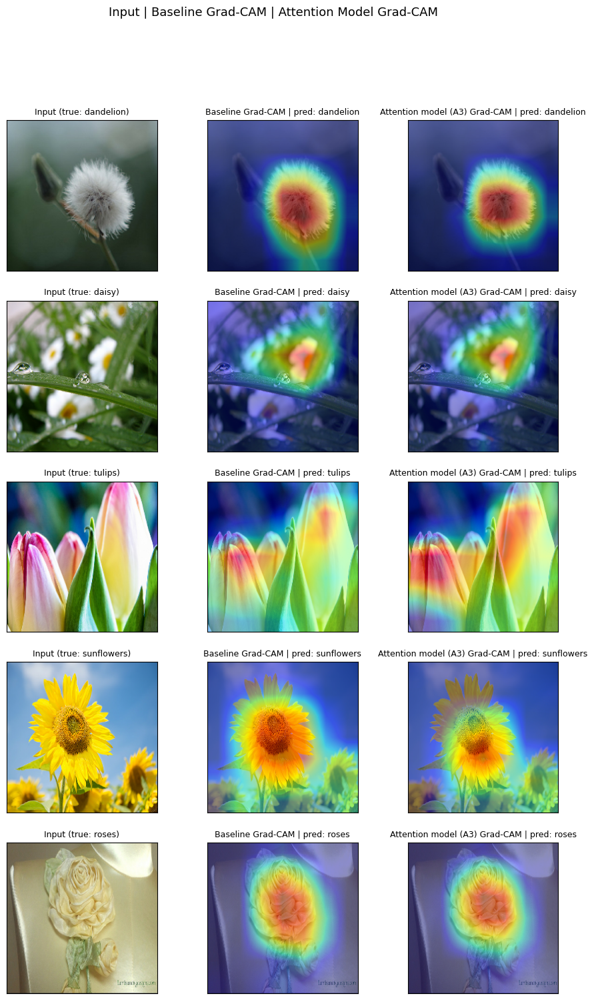

Saved figure -> outputs/figures/09_gradcam_baseline_vs_attention.png


In [25]:
cams = {k: gradcam(k, X_vis) for k in ['A0', SELECTED]}
fig, axes = plt.subplots(len(VIS_IDX), 3, figsize=(11, 3.4 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], f'Input (true: {CLASS_NAMES[y_test[VIS_IDX[r]]]})')
    for j, k in enumerate(['A0', SELECTED]):
        cam, cl = cams[k]
        show_overlay(axes[r, j + 1], I_vis[r], cam[r],
                     f'{"Baseline" if k == "A0" else "Attention model (A3)"} Grad-CAM | pred: {CLASS_NAMES[cl[r]]}')
fig.suptitle('Input | Baseline Grad-CAM | Attention Model Grad-CAM', fontsize=13)
save_fig(fig, '09_gradcam_baseline_vs_attention')                                                # Plot 9

## 25. Attention-Position Visualisation (Spatial Attention at P2, P3, P4)

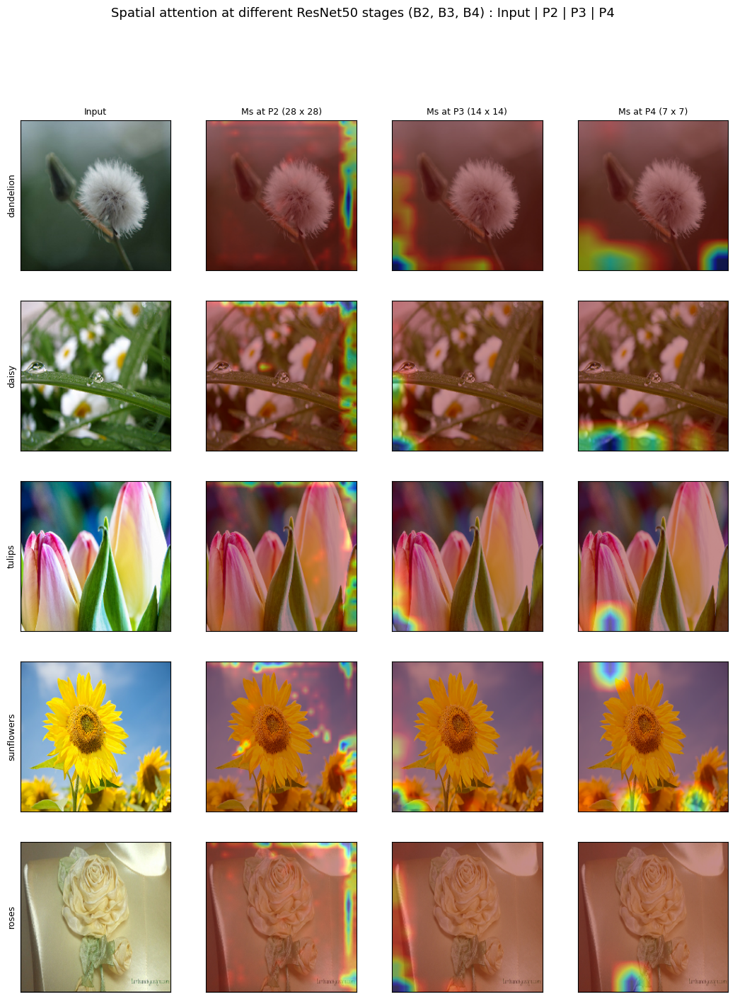

Saved figure -> outputs/figures/13_attention_maps_P2_P3_P4.png


In [26]:
pmaps = {p: spatial_map(k, X_vis, f'att_{p}_sa_map') for k, p in [('B2', 'P2'), ('B3', 'P3'), ('B4', 'P4')]}
fig, axes = plt.subplots(len(VIS_IDX), 4, figsize=(13, 3.2 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    for j, p in enumerate(['P2', 'P3', 'P4']):
        H, W, C = STAGE_DIMS[p]
        show_overlay(axes[r, j + 1], I_vis[r], pmaps[p][r], f'Ms at {p} ({H} x {W})' if r == 0 else None)
fig.suptitle('Spatial attention at different ResNet50 stages (B2, B3, B4) : Input | P2 | P3 | P4', fontsize=13)
save_fig(fig, '13_attention_maps_P2_P3_P4')                                                      # Plot 13

## 26. Qualitative Comparison Across Attention Mechanisms

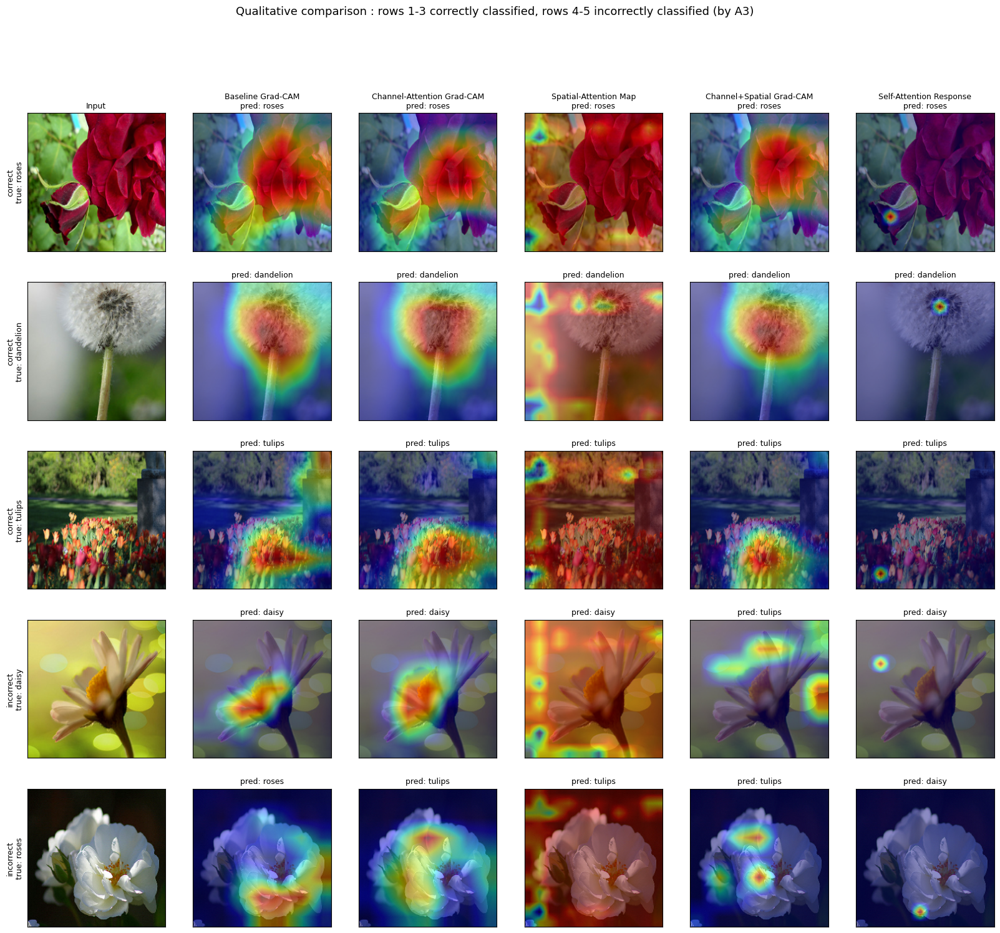

Saved figure -> outputs/figures/14_qualitative_comparison_correct_incorrect.png


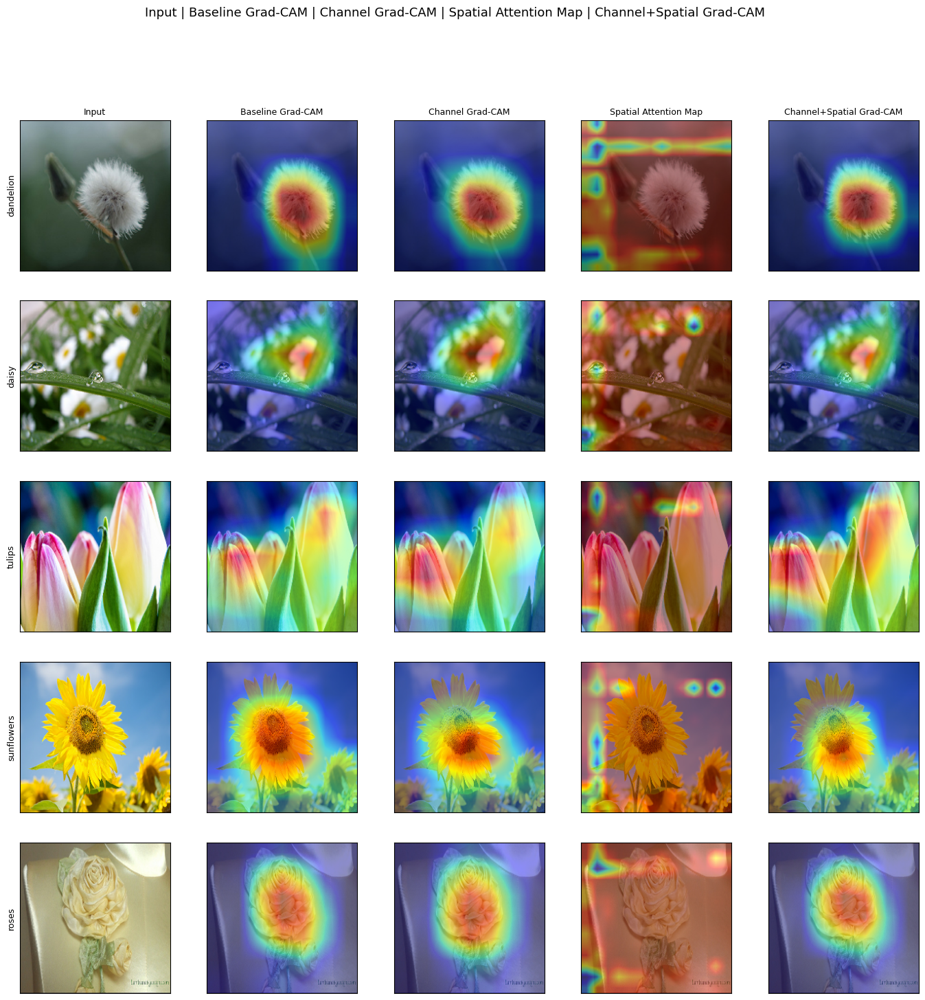

Saved figure -> outputs/figures/18_recommended_layout_gradcam_attention.png


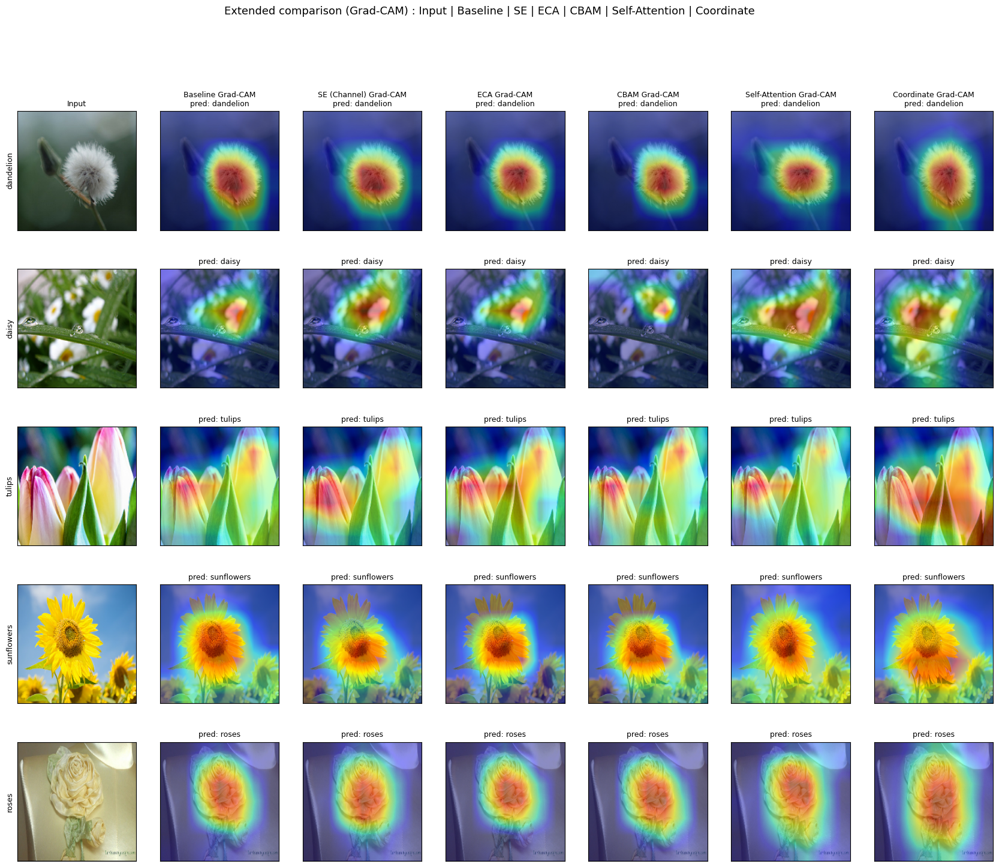

Saved figure -> outputs/figures/19_extended_layout_additional_mechanisms.png


In [27]:
# ---- 3 correctly + 2 incorrectly classified images ----
rng = np.random.RandomState(SEED)
correct = np.where((pA3 == y_test) & (pA0 == y_test))[0]
QUAL_CORRECT, used_cls = [], set()
for i in rng.permutation(correct):
    if y_test[i] not in used_cls:
        QUAL_CORRECT.append(int(i)); used_cls.add(y_test[i])
    if len(QUAL_CORRECT) == 3:
        break
wrong = np.where(pA3 != y_test)[0]
if len(wrong) < 2:
    wrong = np.union1d(wrong, np.where(pA0 != y_test)[0])
QUAL_WRONG = [int(i) for i in rng.permutation(wrong)[:2]]
QUAL_IDX = QUAL_CORRECT + QUAL_WRONG
QUAL_TYPE = ['correct'] * len(QUAL_CORRECT) + ['incorrect'] * len(QUAL_WRONG)
X_q, I_q = X_test_pre[QUAL_IDX], X_test[QUAL_IDX]

# Plot 14 : Input | Baseline GC | Channel GC | Spatial map | C+S GC | Self-attention response
gc_q = {k: gradcam(k, X_q) for k in ['A0', 'A1', 'A3']}
sp_q = spatial_map('A2', X_q)
sa_q = sa_matrix('A4', X_q).mean(1)
cols = ['Input', 'Baseline Grad-CAM', 'Channel-Attention Grad-CAM', 'Spatial-Attention Map',
        'Channel+Spatial Grad-CAM', 'Self-Attention Response']
fig, axes = plt.subplots(len(QUAL_IDX), 6, figsize=(20, 3.4 * len(QUAL_IDX)))
for r in range(len(QUAL_IDX)):
    show_img(axes[r, 0], I_q[r], cols[0] if r == 0 else None,
             ylabel=f'{QUAL_TYPE[r]}\ntrue: {CLASS_NAMES[y_test[QUAL_IDX[r]]]}')
    for j, k in [(1, 'A0'), (2, 'A1'), (4, 'A3')]:
        cam, cl = gc_q[k]
        show_overlay(axes[r, j], I_q[r], cam[r], (cols[j] + '\n' if r == 0 else '') + f'pred: {CLASS_NAMES[cl[r]]}')
    show_overlay(axes[r, 3], I_q[r], sp_q[r], (cols[3] + '\n' if r == 0 else '') + f'pred: {CLASS_NAMES[preds("A2")[QUAL_IDX[r]]]}')
    show_overlay(axes[r, 5], I_q[r], sa_q[r].reshape(Hs, Ws), (cols[5] + '\n' if r == 0 else '') + f'pred: {CLASS_NAMES[preds("A4")[QUAL_IDX[r]]]}')
fig.suptitle('Qualitative comparison : rows 1-3 correctly classified, rows 4-5 incorrectly classified (by A3)', fontsize=13)
save_fig(fig, '14_qualitative_comparison_correct_incorrect')

# Plot 18 : Section 32 layout on the representative images
gc_v = {k: gradcam(k, X_vis) for k in ['A0', 'A1', 'A3', 'SE', 'ECA', 'CBAM', 'A4', 'COORD']}
sp_v = spatial_map('A2', X_vis)
fig, axes = plt.subplots(len(VIS_IDX), 5, figsize=(17, 3.3 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    show_overlay(axes[r, 1], I_vis[r], gc_v['A0'][0][r], 'Baseline Grad-CAM' if r == 0 else None)
    show_overlay(axes[r, 2], I_vis[r], gc_v['A1'][0][r], 'Channel Grad-CAM' if r == 0 else None)
    show_overlay(axes[r, 3], I_vis[r], sp_v[r], 'Spatial Attention Map' if r == 0 else None)
    show_overlay(axes[r, 4], I_vis[r], gc_v['A3'][0][r], 'Channel+Spatial Grad-CAM' if r == 0 else None)
fig.suptitle('Input | Baseline Grad-CAM | Channel Grad-CAM | Spatial Attention Map | Channel+Spatial Grad-CAM', fontsize=13)
save_fig(fig, '18_recommended_layout_gradcam_attention')

# Plot 19 : extended layout Input | Baseline | SE | ECA | CBAM | Self-Attention (+ Coordinate)
EXT = ['A0', 'SE', 'ECA', 'CBAM', 'A4', 'COORD']
fig, axes = plt.subplots(len(VIS_IDX), 1 + len(EXT), figsize=(3.0 * (1 + len(EXT)), 3.3 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    for j, k in enumerate(EXT):
        cam, cl = gc_v[k]
        show_overlay(axes[r, j + 1], I_vis[r], cam[r], (f'{DISPLAY[k]} Grad-CAM\n' if r == 0 else '') + f'pred: {CLASS_NAMES[cl[r]]}')
fig.suptitle('Extended comparison (Grad-CAM) : Input | Baseline | SE | ECA | CBAM | Self-Attention | Coordinate', fontsize=13)
save_fig(fig, '19_extended_layout_additional_mechanisms')

## 27. Additional Exercise Plots (Experiments 3, 4, 5 and Attention-Mechanism Comparison)

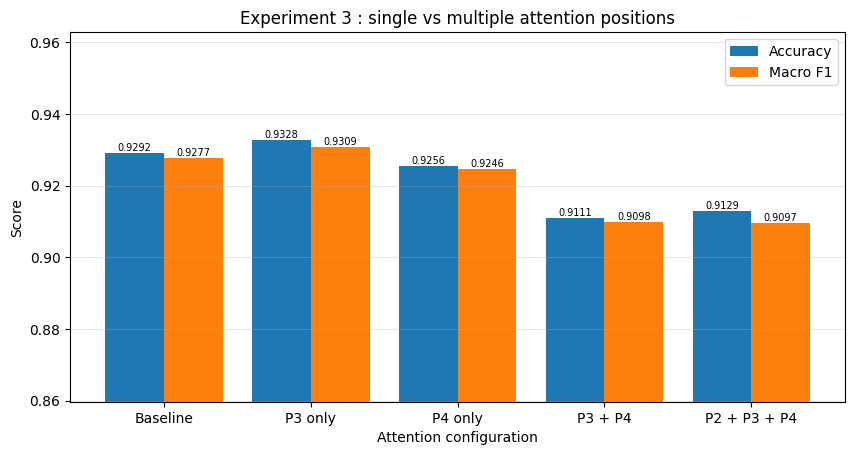

Saved figure -> outputs/figures/20_exp3_multiple_positions_performance.png


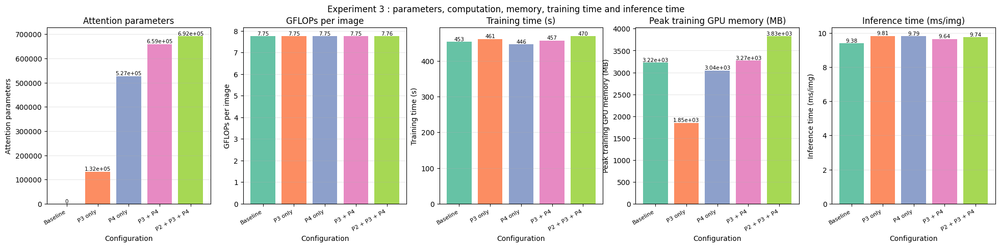

Saved figure -> outputs/figures/21_exp3_multiple_positions_complexity.png


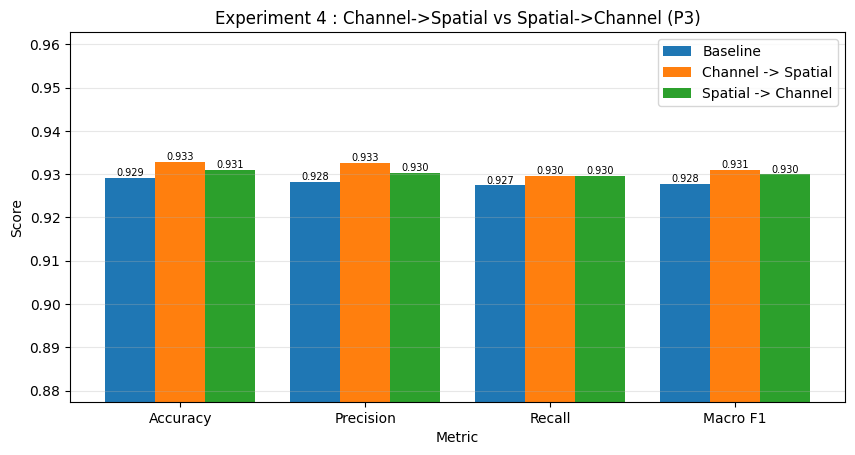

Saved figure -> outputs/figures/22_exp4_attention_order_metrics.png


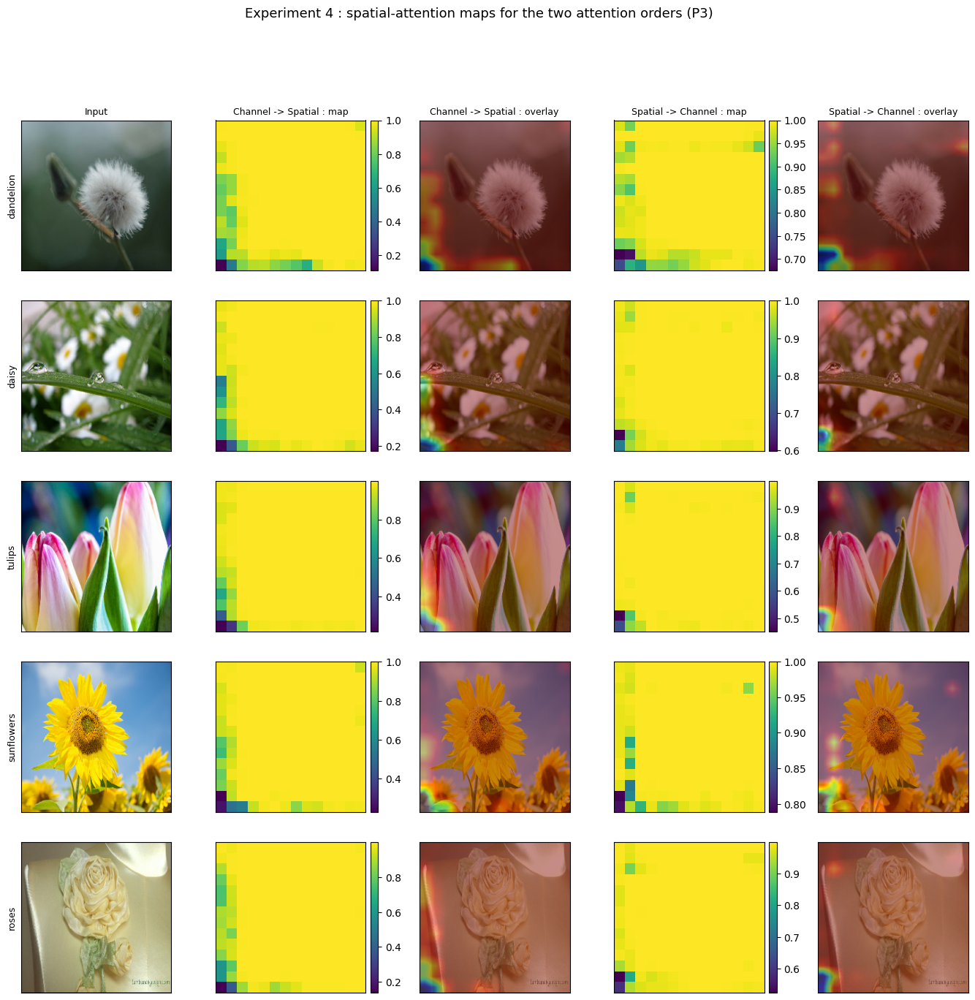

Saved figure -> outputs/figures/23_exp4_attention_order_spatial_maps.png


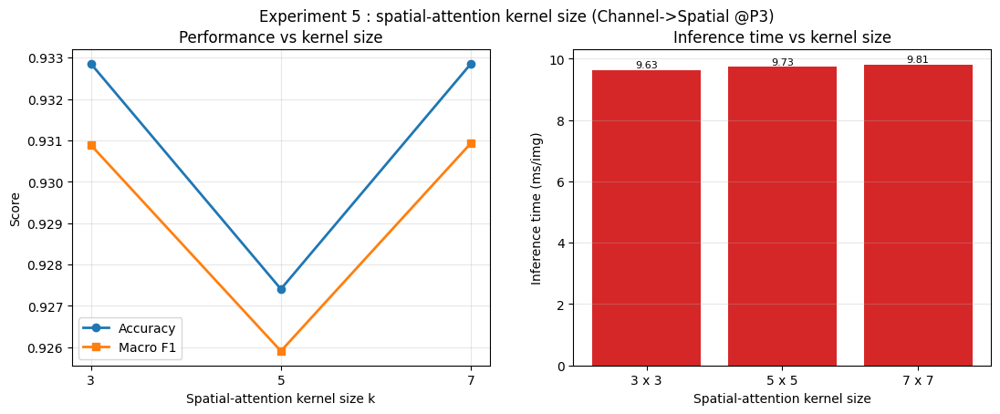

Saved figure -> outputs/figures/24_exp5_kernel_size_metrics.png


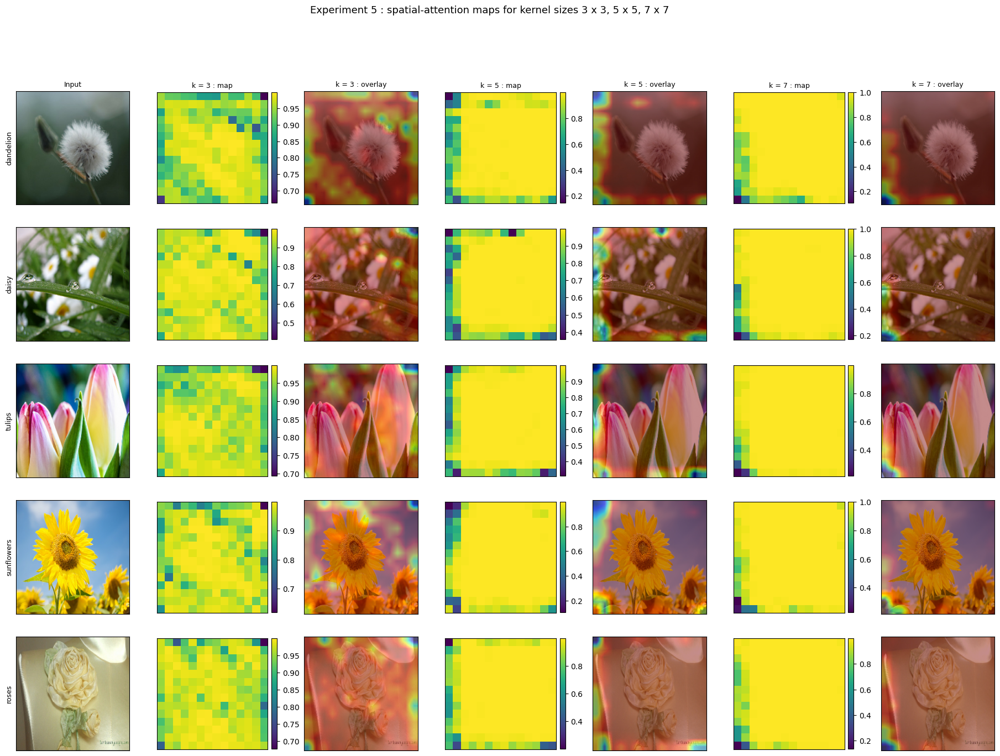

Saved figure -> outputs/figures/25_exp5_kernel_size_spatial_maps.png


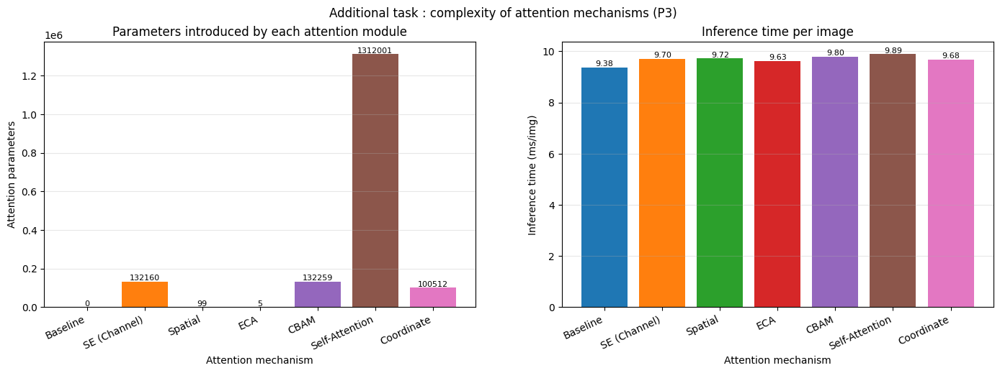

Saved figure -> outputs/figures/26_additional_mechanisms_complexity.png


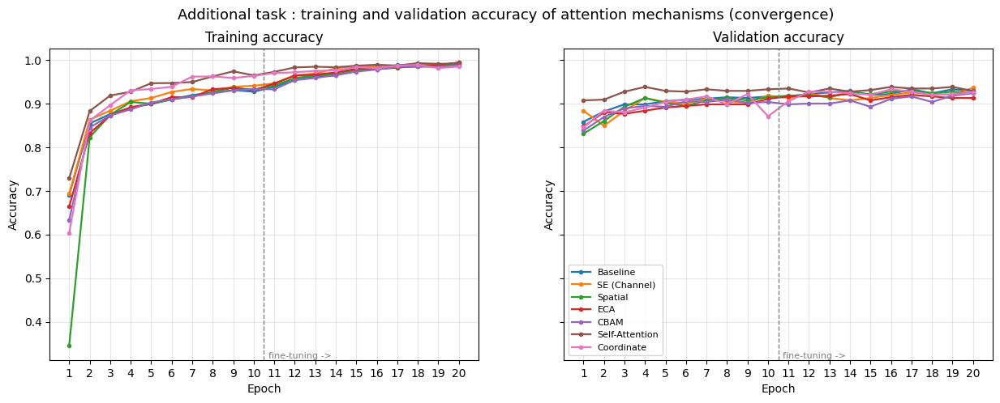

Saved figure -> outputs/figures/27_additional_mechanisms_convergence.png


In [28]:
# ---------- Experiment 3 : multiple attention positions ----------
mk3 = GROUPS['exp3_multiple_positions']
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(mk3))
b1 = ax.bar(x - 0.2, [R(k, 'test_accuracy') for k in mk3], 0.4, label='Accuracy')
b2 = ax.bar(x + 0.2, [R(k, 'macro_f1') for k in mk3], 0.4, label='Macro F1')
ax.bar_label(b1, fmt='%.4f', fontsize=7); ax.bar_label(b2, fmt='%.4f', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([DISPLAY[k] for k in mk3])
v = [R(k, m) for k in mk3 for m in ('test_accuracy', 'macro_f1')]
ax.set_ylim(max(0, min(v) - 0.05), min(1.0, max(v) + 0.03))
ax.set_xlabel('Attention configuration'); ax.set_ylabel('Score')
ax.set_title('Experiment 3 : single vs multiple attention positions'); ax.legend(); ax.grid(axis='y', alpha=0.3)
save_fig(fig, '20_exp3_multiple_positions_performance')

cost_metrics = [('attention_params', 'Attention parameters'), ('gflops', 'GFLOPs per image'),
                ('train_time_s', 'Training time (s)'), ('peak_train_gpu_mem_mb', 'Peak training GPU memory (MB)'),
                ('inference_ms_per_image', 'Inference time (ms/img)')]
fig, axes = plt.subplots(1, len(cost_metrics), figsize=(24, 4.5))
for ax, (m, lab) in zip(axes, cost_metrics):
    b = ax.bar([DISPLAY[k] for k in mk3], [R(k, m) for k in mk3], color=sns.color_palette('Set2', len(mk3)))
    ax.bar_label(b, fmt='%.3g', fontsize=7.5)
    ax.set_title(lab); ax.set_xlabel('Configuration'); ax.set_ylabel(lab)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right', fontsize=8); ax.grid(axis='y', alpha=0.3)
fig.suptitle('Experiment 3 : parameters, computation, memory, training time and inference time')
save_fig(fig, '21_exp3_multiple_positions_complexity')

# ---------- Experiment 4 : attention order ----------
ok = GROUPS['exp4_attention_order']
mets = [('test_accuracy', 'Accuracy'), ('macro_precision', 'Precision'), ('macro_recall', 'Recall'), ('macro_f1', 'Macro F1')]
fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(mets))
for j, k in enumerate(ok):
    b = ax.bar(x + (j - 1) * 0.27, [R(k, m) for m, _ in mets], 0.27, label=DISPLAY[k])
    ax.bar_label(b, fmt='%.3f', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels([l for _, l in mets])
v = [R(k, m) for k in ok for m, _ in mets]
ax.set_ylim(max(0, min(v) - 0.05), min(1.0, max(v) + 0.03))
ax.set_xlabel('Metric'); ax.set_ylabel('Score'); ax.set_title('Experiment 4 : Channel->Spatial vs Spatial->Channel (P3)')
ax.legend(); ax.grid(axis='y', alpha=0.3)
save_fig(fig, '22_exp4_attention_order_metrics')

omaps = {k: spatial_map(k, X_vis) for k in ['O_CS', 'O_SC']}
fig, axes = plt.subplots(len(VIS_IDX), 5, figsize=(17, 3.1 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    for j, k in enumerate(['O_CS', 'O_SC']):
        show_map(fig, axes[r, 1 + 2 * j], omaps[k][r], f'{DISPLAY[k]} : map' if r == 0 else None)
        show_overlay(axes[r, 2 + 2 * j], I_vis[r], omaps[k][r], f'{DISPLAY[k]} : overlay' if r == 0 else None)
fig.suptitle('Experiment 4 : spatial-attention maps for the two attention orders (P3)', fontsize=13)
save_fig(fig, '23_exp4_attention_order_spatial_maps')

# ---------- Experiment 5 : spatial-attention kernel size ----------
kk, ksz = ['K3', 'K5', 'K7'], [3, 5, 7]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ksz, [R(k, 'test_accuracy') for k in kk], marker='o', lw=2, label='Accuracy')
axes[0].plot(ksz, [R(k, 'macro_f1') for k in kk], marker='s', lw=2, label='Macro F1')
axes[0].set_xticks(ksz); axes[0].set_xlabel('Spatial-attention kernel size k'); axes[0].set_ylabel('Score')
axes[0].set_title('Performance vs kernel size'); axes[0].legend(); axes[0].grid(alpha=0.3)
b = axes[1].bar([f'{k} x {k}' for k in ksz], [R(k, 'inference_ms_per_image') for k in kk], color='tab:red')
axes[1].bar_label(b, fmt='%.2f', fontsize=8)
axes[1].set_xlabel('Spatial-attention kernel size'); axes[1].set_ylabel('Inference time (ms/img)')
axes[1].set_title('Inference time vs kernel size'); axes[1].grid(axis='y', alpha=0.3)
fig.suptitle('Experiment 5 : spatial-attention kernel size (Channel->Spatial @P3)')
save_fig(fig, '24_exp5_kernel_size_metrics')

kmaps = {k: spatial_map(k, X_vis) for k in kk}
fig, axes = plt.subplots(len(VIS_IDX), 7, figsize=(23, 3.1 * len(VIS_IDX)))
for r in range(len(VIS_IDX)):
    show_img(axes[r, 0], I_vis[r], 'Input' if r == 0 else None, ylabel=CLASS_NAMES[y_test[VIS_IDX[r]]])
    for j, k in enumerate(kk):
        show_map(fig, axes[r, 1 + 2 * j], kmaps[k][r], f'{DISPLAY[k]} : map' if r == 0 else None)
        show_overlay(axes[r, 2 + 2 * j], I_vis[r], kmaps[k][r], f'{DISPLAY[k]} : overlay' if r == 0 else None)
fig.suptitle('Experiment 5 : spatial-attention maps for kernel sizes 3 x 3, 5 x 5, 7 x 7', fontsize=13)
save_fig(fig, '25_exp5_kernel_size_spatial_maps')

# ---------- Additional task : comparison of attention mechanisms ----------
ak = GROUPS['additional_mechanisms']
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))
bar_metric(axes[0], ak, 'attention_params', 'Attention parameters', zoom=False, fmt='%d')
axes[0].set_xlabel('Attention mechanism'); axes[0].set_title('Parameters introduced by each attention module')
bar_metric(axes[1], ak, 'inference_ms_per_image', 'Inference time (ms/img)', zoom=False, fmt='%.2f')
axes[1].set_xlabel('Attention mechanism'); axes[1].set_title('Inference time per image')
fig.suptitle('Additional task : complexity of attention mechanisms (P3)')
save_fig(fig, '26_additional_mechanisms_complexity')

plot_curves(ak, 'accuracy', '27_additional_mechanisms_convergence',
            'Additional task : training and validation accuracy of attention mechanisms (convergence)')

## 28. Zip the outputs/ Folder for Download

In [29]:
release_models()
n_fig = len([f for f in os.listdir(FIG_DIR) if f.endswith('.png')])
n_csv = len([f for f in os.listdir(OUT_DIR) if f.endswith('.csv')])
zip_path = shutil.make_archive('CS3807_Exp8_9_outputs', 'zip', root_dir='.', base_dir=OUT_DIR)
print(f'{n_fig} figures (.png, 150 DPI) and {n_csv} result tables (.csv) archived.')
print(f'ZIP: {os.path.abspath(zip_path)} ({os.path.getsize(zip_path) / 2**20:.1f} MB)')
display(FileLink(zip_path))

27 figures (.png, 150 DPI) and 13 result tables (.csv) archived.
ZIP: /kaggle/working/CS3807_Exp8_9_outputs.zip (28.1 MB)


/kaggle/working/CS3807_Exp8_9_outputs.zip